In [3]:
import anndata as ad
import numpy as np
import pandas as pd
import SDP_miRNA.dataset
import SDP_miRNA.optimization
import SDP_miRNA.optimization_MOSEK
import SDP_miRNA.correlation
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

In [4]:
rng = np.random.default_rng(423)

# Subsampling

Randomly select cells to form datasets with the same size as G1 and S & G2M

In [26]:
# load pcRNA
adata_pcRNA = ad.read_h5ad("TotalX_HEK293T_CC_pcRNA.h5ad")

# load miRNA
adata_miRNA = ad.read_h5ad("TotalX_HEK293T_CC_miRNA.h5ad")

# load capture
beta = np.loadtxt("../HEK293T/TotalX_HEK293T_capture.txt")

In [27]:
# cells per phase
cell_cycle_counts = adata_pcRNA.obs['phase'].value_counts()
cell_cycle_counts

phase
S      6285
G2M    5217
G1      443
Name: count, dtype: int64

In [35]:
# size
N = adata_pcRNA.n_obs
N1 = cell_cycle_counts.loc['G1']
N2 = cell_cycle_counts.loc['G2M']

# cell selection
selection_1 = rng.choice(N, N1, replace=False)
selection_2 = rng.choice(N, N2, replace=False)

# indicator
mask_1 = np.array([True if i in selection_1 else False for i in range(N)])
mask_2 = np.array([True if i in selection_2 else False for i in range(N)])

# store
adata_pcRNA.obs['Subsample_1'] = mask_1
adata_pcRNA.obs['Subsample_2'] = mask_2
adata_miRNA.obs['Subsample_1'] = mask_1
adata_miRNA.obs['Subsample_2'] = mask_2

# split capture
beta_1 = beta[mask_1]
beta_2 = beta[mask_2]

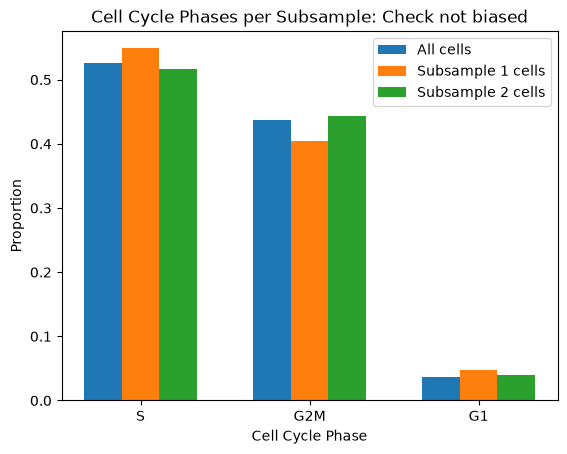

In [96]:
split_all = adata_pcRNA.obs.phase.value_counts()
split_N1 = adata_pcRNA[adata_pcRNA.obs['Subsample_1'], :].obs.phase.value_counts()
split_N2 = adata_pcRNA[adata_pcRNA.obs['Subsample_2'], :].obs.phase.value_counts()

dist_all = split_all.values / split_all.values.sum()
dist_N1 = split_N1.values / split_N1.values.sum()
dist_N2 = split_N2.values / split_N2.values.sum()

dists = {
    'All cells': dist_all,
    'Subsample 1 cells': dist_N1,
    'Subsample 2 cells': dist_N2
}

fig, axs = plt.subplots()
axs.grouped_bar(dists)
axs.set_ylabel("Proportion")
axs.set_xticks([0, 1, 2])
axs.set_xticklabels(["S", "G2M", "G1"])
axs.set_xlabel("Cell Cycle Phase")
axs.legend()
axs.set_title("Cell Cycle Phases per Subsample: Check not biased")
plt.show()

In [ ]:
# save counts with cell cycle info
#adata_pcRNA.write_h5ad("./Subsampling-data/TotalX_HEK293T_SS_pcRNA.h5ad")
#adata_miRNA.write_h5ad("./Subsampling-data/TotalX_HEK293T_SS_miRNA.h5ad")

# save capture
#np.savetxt("./Subsampling-data/TotalX_HEK293T_SS1_capture.txt", beta_1)
#np.savetxt("./Subsampling-data/TotalX_HEK293T_SS2_capture.txt", beta_2)

# miRNA - miRNA correlations

In [179]:
# load pcRNA
adata_pcRNA = ad.read_h5ad("./Subsampling-data/TotalX_HEK293T_SS_pcRNA.h5ad")

# load miRNA
adata_miRNA = ad.read_h5ad("./Subsampling-data/TotalX_HEK293T_SS_miRNA.h5ad")

# load capture
beta_N1 = np.loadtxt("./Subsampling-data/TotalX_HEK293T_SS1_capture.txt")
beta_N2 = np.loadtxt("./Subsampling-data/TotalX_HEK293T_SS2_capture.txt")

In [180]:
# additional miRNA selection

# max observed count per miRNA
max_count = adata_miRNA.X.max(axis=0).toarray()

# select
count_mask = (max_count >= 3).squeeze()
miRNA_idxs = np.arange(len(count_mask))[count_mask]

# subset miRNA
adata_miRNA = adata_miRNA[:, miRNA_idxs]

# display
print(f"{sum(count_mask)} / {len(count_mask)} miRNA retained")

20 / 41 miRNA retained


In [190]:
# consider all miRNA (additional selection)
L = adata_miRNA.n_vars

# select all gene pairs: no repeats
Is, Js = np.triu_indices(L, k=1)
gene_queries = [
    [[int(i)], [int(j)]] for i, j in zip(Is, Js)
]

# initialize dataset
SDP_data = SDP_miRNA.dataset.Dataset()
SDP_data_N1 = SDP_miRNA.dataset.Dataset()
SDP_data_N2 = SDP_miRNA.dataset.Dataset()

# construct pairs
SDP_data.construct_dataset_adata(adata_miRNA, adata_miRNA, beta, gene_queries)
SDP_data_N1.construct_dataset_adata(adata_miRNA[adata_miRNA.obs['Subsample_1']], adata_miRNA[adata_miRNA.obs['Subsample_1']], beta_N1, gene_queries)
SDP_data_N2.construct_dataset_adata(adata_miRNA[adata_miRNA.obs['Subsample_2']], adata_miRNA[adata_miRNA.obs['Subsample_2']], beta_N2, gene_queries)

# bootstrap
SDP_data.bootstrap(d=3)
SDP_data_N1.bootstrap(d=3)
SDP_data_N2.bootstrap(d=3)

100%|██████████| 2/2 [00:00<00:00,  2.66it/s]


In [191]:
# model free independence test
MF_ind = SDP_miRNA.optimization.ModelFreeOptimization(SDP_data, d=3)
MF_ind.optimized_construction = True
MF_ind.analyse_dataset()

MF_ind_N1 = SDP_miRNA.optimization.ModelFreeOptimization(SDP_data_N1, d=3)
MF_ind_N1.optimized_construction = True
MF_ind_N1.analyse_dataset()

MF_ind_N2 = SDP_miRNA.optimization.ModelFreeOptimization(SDP_data_N2, d=3)
MF_ind_N2.optimized_construction = True
MF_ind_N2.analyse_dataset()

100%|██████████| 190/190 [00:01<00:00, 123.14it/s]


In [192]:
# model free interacting H&R
MF_int = SDP_miRNA.optimization_MOSEK.MOSEKModelFreeInteracting(SDP_data, d=3)
#MF_int.use_optimized_hit_and_run = True
MF_int.analyse_dataset()

MF_int_N1 = SDP_miRNA.optimization_MOSEK.MOSEKModelFreeInteracting(SDP_data_N1, d=3)
#MF_int_N1.use_optimized_hit_and_run = True
MF_int_N1.analyse_dataset()

MF_int_N2 = SDP_miRNA.optimization_MOSEK.MOSEKModelFreeInteracting(SDP_data_N2, d=3)
#MF_int_N2.use_optimized_hit_and_run = True
MF_int_N2.analyse_dataset()

100%|██████████| 190/190 [01:00<00:00,  3.14it/s]


In [193]:
# optimized H&R code
for opt in [MF_int, MF_int_N1, MF_int_N2]:
    print(f"Interval err: {np.unique([dct['err'] for dct in opt.HAR_metrics_dict.values()], return_counts=True)}")
    print(f"Interval eps: {np.unique([dct['eps'] for dct in opt.HAR_metrics_dict.values()], return_counts=True)}\n")

Interval err: (array([0]), array([190]))
Interval eps: (array([0]), array([190]))

Interval err: (array([0]), array([190]))
Interval eps: (array([  0, 999]), array([179,  11]))

Interval err: (array([0]), array([190]))
Interval eps: (array([0]), array([190]))



In [194]:
# current H&R code
for opt in [MF_int, MF_int_N1, MF_int_N2]:
    print(f"Interval err: {np.unique([dct['err'] for dct in opt.HAR_metrics_dict.values()], return_counts=True)}")
    print(f"Interval eps: {np.unique([dct['eps'] for dct in opt.HAR_metrics_dict.values()], return_counts=True)}\n")

Interval err: (array([0]), array([190]))
Interval eps: (array([0]), array([190]))

Interval err: (array([0]), array([190]))
Interval eps: (array([  0, 999]), array([179,  11]))

Interval err: (array([0]), array([190]))
Interval eps: (array([0]), array([190]))



In [195]:
# H&R correlations
_, HAR_intervals = MF_int.compute_dataset_correlation()
HAR_mid = (HAR_intervals[:, 0] + HAR_intervals[:, 1]) / 2

_, HAR_intervals_N1 = MF_int_N1.compute_dataset_correlation()
HAR_mid_N1 = (HAR_intervals_N1[:, 0] + HAR_intervals_N1[:, 1]) / 2

_, HAR_intervals_N2 = MF_int_N2.compute_dataset_correlation()
HAR_mid_N2 = (HAR_intervals_N2[:, 0] + HAR_intervals_N2[:, 1]) / 2

100%|██████████| 190/190 [00:02<00:00, 93.03it/s]


In [196]:
all_matrix_mid = np.zeros((L, L)) * np.nan
N1_matrix_mid = np.zeros((L, L)) * np.nan
N2_matrix_mid = np.zeros((L, L)) * np.nan

all_matrix_lb = np.zeros((L, L)) * np.nan
N1_matrix_lb = np.zeros((L, L)) * np.nan
N2_matrix_lb = np.zeros((L, L)) * np.nan

all_matrix_ub = np.zeros((L, L)) * np.nan
N1_matrix_ub = np.zeros((L, L)) * np.nan
N2_matrix_ub = np.zeros((L, L)) * np.nan

for i, query in enumerate(SDP_data.gene_queries):
    if MF_ind.result_dict[i]['status'] == "INFEASIBLE":
        all_matrix_mid[query[0][0], query[1][0]] = HAR_mid[i]
        all_matrix_lb[query[0][0], query[1][0]] = HAR_intervals[i, 0]
        all_matrix_ub[query[0][0], query[1][0]] = HAR_intervals[i, 1]
    if MF_ind_N1.result_dict[i]['status'] == "INFEASIBLE":
        N1_matrix_mid[query[0][0], query[1][0]] = HAR_mid_N1[i]
        N1_matrix_lb[query[0][0], query[1][0]] = HAR_intervals_N1[i, 0]
        N1_matrix_ub[query[0][0], query[1][0]] = HAR_intervals_N1[i, 1]
    if MF_ind_N2.result_dict[i]['status'] == "INFEASIBLE":
        N2_matrix_mid[query[0][0], query[1][0]] = HAR_mid_N2[i]
        N2_matrix_lb[query[0][0], query[1][0]] = HAR_intervals_N2[i, 0]
        N2_matrix_ub[query[0][0], query[1][0]] = HAR_intervals_N2[i, 1]

In [211]:
def miRNA_heatmat_plot(all_matrix, N1_matrix, N2_matrix, stat):

    cmap = LinearSegmentedColormap.from_list('a', ['red', 'white', 'blue'])
    fig, axs = plt.subplots(1, 4, figsize=(12, 4), gridspec_kw={'width_ratios': [1, 1, 1, 0.1]}, constrained_layout=True)
    im = axs[0].imshow(all_matrix, cmap=cmap, vmin=-1, vmax=1)
    im = axs[1].imshow(N1_matrix, cmap=cmap, vmin=-1, vmax=1)
    im = axs[2].imshow(N2_matrix, cmap=cmap, vmin=-1, vmax=1)
    axs[0].set_xlabel("All cells")
    axs[1].set_xlabel("N1 (G1 size)")
    axs[2].set_xlabel("N2 (S & G2M size)")
    RNA_labels = adata_miRNA.var['GeneName'].tolist()
    for i in range(3):
        axs[i].set_xticks(range(L))
        axs[i].set_xticklabels([""] * L, rotation=90)
        axs[i].set_yticks(range(L))
        axs[i].set_yticklabels([""] * L)
    axs[0].set_yticklabels(RNA_labels)
    fig.supxlabel("Subsampled Cells")
    fig.suptitle("microRNA - microRNA correlations: Subsampling control for cell cycle effect")
    plt.colorbar(im, cax=axs[3], label=f"Correlation (H&R {stat})")
    plt.show()

## Correlation midpoint

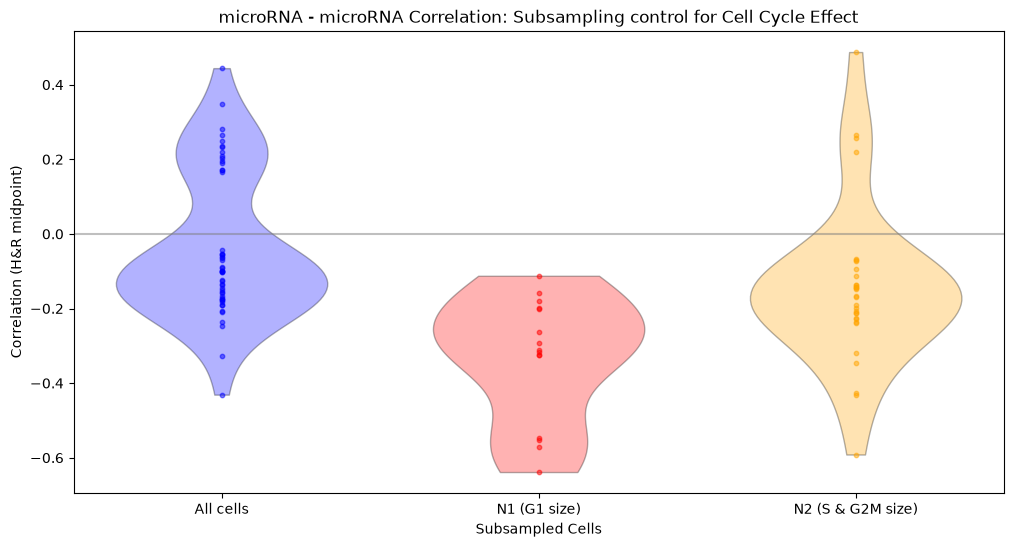

In [214]:
fig, axs = plt.subplots(figsize=(12, 6))
k = 2
plot_colors = ["blue", "red", "orange"]
plot_data_list = [
    all_matrix_mid[np.triu_indices(L, k=1)],
    N1_matrix_mid[np.triu_indices(L, k=1)],
    N2_matrix_mid[np.triu_indices(L, k=1)]
]
total_size = sum([dt.size for dt in plot_data_list])
for i, plot_data in enumerate(plot_data_list):
    vp = axs.violinplot(
        dataset=plot_data,
        positions=[i],
        showextrema=False,
        side="both",
        widths=k * (plot_data.size / total_size)
    )
    plt.setp(vp['bodies'], facecolor=plot_colors[i], edgecolor='black')
    plt.scatter([i] * len(plot_data), plot_data, color=plot_colors[i], alpha=0.5, s=10)
axs.axhline(0, color="grey", alpha=0.5)
axs.set_xticks([0, 1, 2])
axs.set_xticklabels(["All cells", "N1 (G1 size)", "N2 (S & G2M size)"])
axs.set_xlabel("Subsampled Cells")
axs.set_ylabel(f"Correlation (H&R midpoint)")
axs.set_title("microRNA - microRNA Correlation: Subsampling control for Cell Cycle Effect")
plt.show()

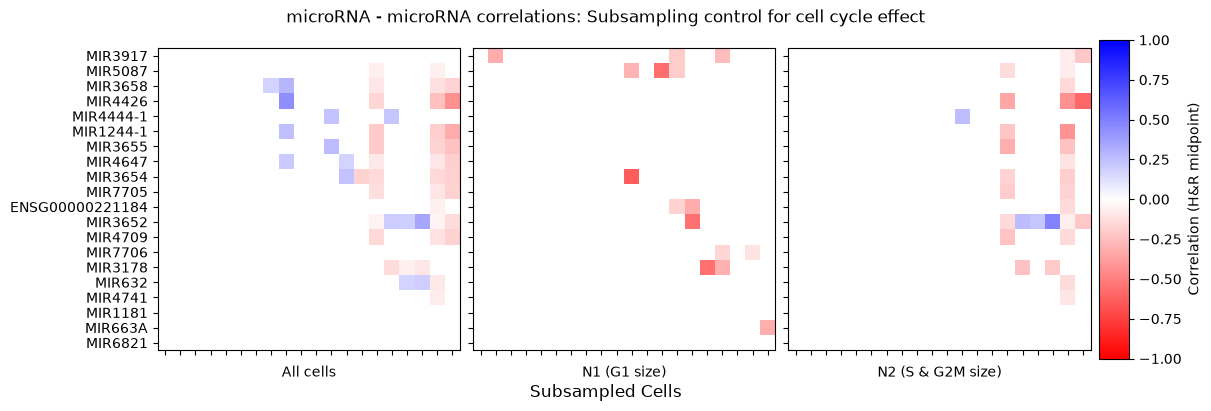

In [215]:
miRNA_heatmat_plot(all_matrix_mid, N1_matrix_mid, N2_matrix_mid, "midpoint")

## Correlation Intervals

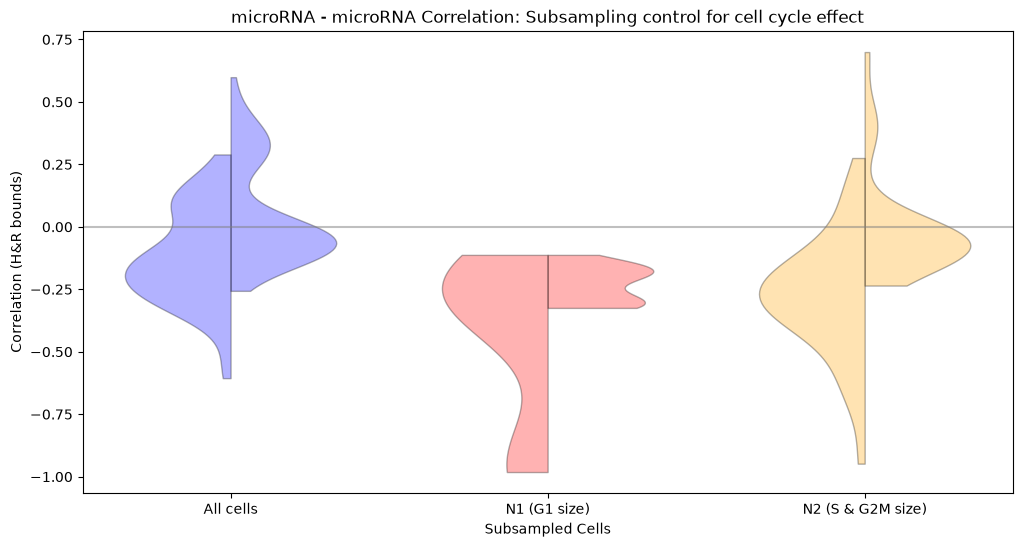

In [216]:
fig, axs = plt.subplots(figsize=(12, 6))
k = 2
plot_colors = ["blue", "red", "orange", "green"]
plot_data_list_lb = [
    all_matrix_lb[np.triu_indices(L, k=1)],
    N1_matrix_lb[np.triu_indices(L, k=1)],
    N2_matrix_lb[np.triu_indices(L, k=1)]
]
plot_data_list_ub = [
    all_matrix_ub[np.triu_indices(L, k=1)],
    N1_matrix_ub[np.triu_indices(L, k=1)],
    N2_matrix_ub[np.triu_indices(L, k=1)]
]
total_size_lb = sum([dt.size for dt  in plot_data_list_lb])
total_size_ub = sum([dt.size for dt  in plot_data_list_ub])
for i, (plot_data_lb, plot_data_ub) in enumerate(zip(plot_data_list_lb, plot_data_list_ub)):
    vp = axs.violinplot(
        dataset=plot_data_lb,
        positions=[i],
        showextrema=False,
        side="low",
        widths=k * (plot_data_lb.size / total_size_lb)
    )
    plt.setp(vp['bodies'], facecolor=plot_colors[i], edgecolor='black')
    vp = axs.violinplot(
        dataset=plot_data_ub,
        positions=[i],
        showextrema=False,
        side="high",
        widths=k * (plot_data_ub.size / total_size_ub)
    )
    plt.setp(vp['bodies'], facecolor=plot_colors[i], edgecolor='black')
axs.axhline(0, color="grey", alpha=0.5)
axs.set_xticks([0, 1, 2])
axs.set_xticklabels(["All cells", "N1 (G1 size)", "N2 (S & G2M size)"])
axs.set_xlabel("Subsampled Cells")
axs.set_ylabel(f"Correlation (H&R bounds)")
axs.set_title("microRNA - microRNA Correlation: Subsampling control for cell cycle effect")
plt.show()

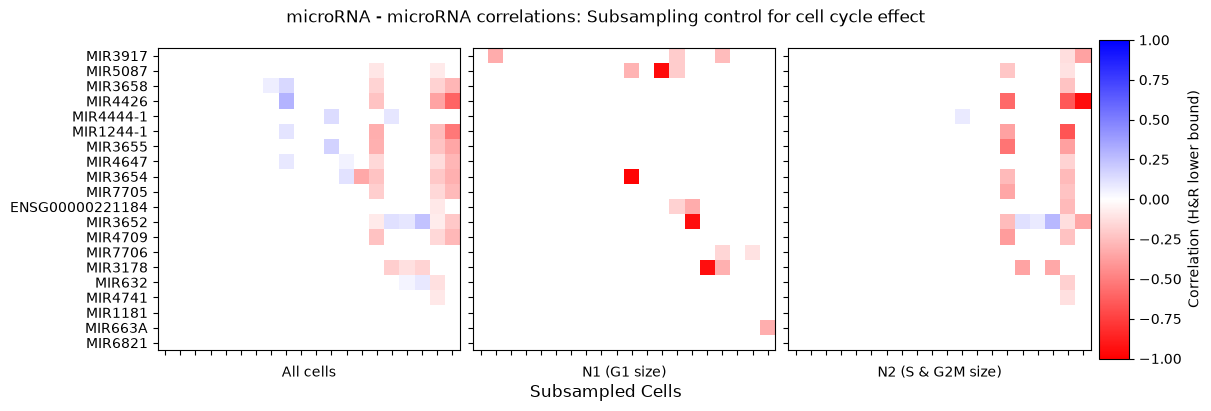

In [217]:
miRNA_heatmat_plot(all_matrix_lb, N1_matrix_lb, N2_matrix_lb, "lower bound")

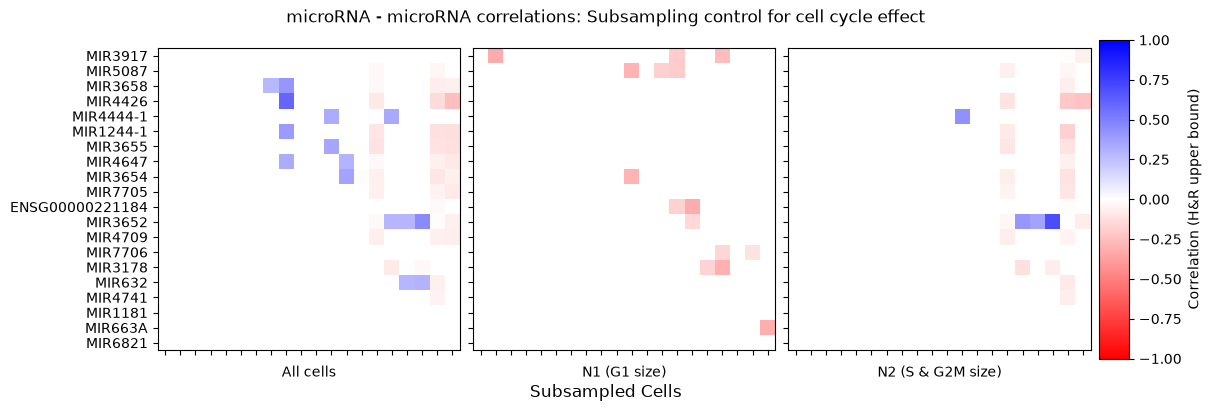

In [218]:
miRNA_heatmat_plot(all_matrix_ub, N1_matrix_ub, N2_matrix_ub, "upper bound")

# miRNA - mRNA Correlations

In [43]:
# load pcRNA
adata_pcRNA = ad.read_h5ad("./Subsampling-data/TotalX_HEK293T_SS_pcRNA.h5ad")

# load miRNA
adata_miRNA = ad.read_h5ad("./Subsampling-data/TotalX_HEK293T_SS_miRNA.h5ad")

# load capture
beta_N1 = np.loadtxt("./Subsampling-data/TotalX_HEK293T_SS1_capture.txt")
beta_N2 = np.loadtxt("./Subsampling-data/TotalX_HEK293T_SS2_capture.txt")

In [44]:
# additional miRNA selection

# max observed count per miRNA
max_count = adata_miRNA.X.max(axis=0).toarray()

# select
count_mask = (max_count >= 3).squeeze()
miRNA_idxs = np.arange(len(count_mask))[count_mask]

# subset miRNA
adata_miRNA = adata_miRNA[:, miRNA_idxs]

# display
print(f"{sum(count_mask)} / {len(count_mask)} miRNA retained")

20 / 41 miRNA retained


## H&R Optimization

In [ ]:
def miRNA_mRNA_correlation_pipeline(miRNA):

    # settings
    d = 3

    # get pcRNA names
    pcRNA_names = adata_pcRNA.var['GeneName'].tolist()

    # initialize result dataframes
    MF_ind_df = pd.DataFrame(index=pcRNA_names)
    MF_int_df = pd.DataFrame(index=pcRNA_names)

    # initialize datasets
    SDP_data_N1 = SDP_miRNA.dataset.Dataset()
    SDP_data_N2 = SDP_miRNA.dataset.Dataset()

    # construct datasets
    SDP_data_N1.construct_dataset_adata(
        adata_miRNA[adata_miRNA.obs['Subsample_1'], adata_miRNA.var['GeneName'] == miRNA],
        adata_pcRNA[adata_pcRNA.obs['Subsample_1'], :],
        beta_N1
    )
    SDP_data_N2.construct_dataset_adata(
        adata_miRNA[adata_miRNA.obs['Subsample_2'], adata_miRNA.var['GeneName'] == miRNA],
        adata_pcRNA[adata_pcRNA.obs['Subsample_2'], :],
        beta_N2
    )

    # bootstrap
    SDP_data_N1.bootstrap(d=d)
    SDP_data_N2.bootstrap(d=d)

    # model free independence test
    MF_ind_N1 = SDP_miRNA.optimization.ModelFreeOptimization(SDP_data_N1, d=d)
    MF_ind_N1.optimized_construction = True
    MF_ind_N1.analyse_dataset()

    MF_ind_N2 = SDP_miRNA.optimization.ModelFreeOptimization(SDP_data_N2, d=d)
    MF_ind_N2.optimized_construction = True
    MF_ind_N2.analyse_dataset()

    # extract results
    status_N1 = np.array([sol['status'] for sol in MF_ind_N1.result_dict.values()])
    status_N2 = np.array([sol['status'] for sol in MF_ind_N2.result_dict.values()])

    # store
    MF_ind_df[f'{miRNA}_N1_status'] = status_N1
    MF_ind_df[f'{miRNA}_N2_status'] = status_N2

    # select indices of interacting pairs
    int_idxs_N1 = np.arange(status_N1.size)[status_N1 == "INFEASIBLE"]
    int_idxs_N2 = np.arange(status_N2.size)[status_N2 == "INFEASIBLE"]
    
    # reduce gene queries to these
    gene_queries_N1 = [query for i, query in enumerate(SDP_data_N1.gene_queries) if i in int_idxs_N1]
    gene_queries_N2 = [query for i, query in enumerate(SDP_data_N2.gene_queries) if i in int_idxs_N2]

    # reduce dataset to interacting pairs
    SDP_data_N1.gene_queries = gene_queries_N1
    SDP_data_N1.total_gene_queries = len(gene_queries_N1)
    SDP_data_N1.moment_bounds = SDP_data_N1.moment_bounds[:, int_idxs_N1, :]

    SDP_data_N2.gene_queries = gene_queries_N2
    SDP_data_N2.total_gene_queries = len(gene_queries_N2)
    SDP_data_N2.moment_bounds = SDP_data_N2.moment_bounds[:, int_idxs_N2, :]

    # model free interacting H&R
    MF_int_N1 = SDP_miRNA.optimization_MOSEK.MOSEKModelFreeInteracting(SDP_data_N1, d=d)
    MF_int_N1.analyse_dataset()

    MF_int_N2 = SDP_miRNA.optimization_MOSEK.MOSEKModelFreeInteracting(SDP_data_N2, d=d)
    MF_int_N2.analyse_dataset()
    
    # H&R correlations
    _, HAR_intervals_N1 = MF_int_N1.compute_dataset_correlation()
    HAR_mid_N1 = (HAR_intervals_N1[:, 0] + HAR_intervals_N1[:, 1]) / 2

    _, HAR_intervals_N2 = MF_int_N2.compute_dataset_correlation()
    HAR_mid_N2 = (HAR_intervals_N2[:, 0] + HAR_intervals_N2[:, 1]) / 2

    # embedd MF int results (only on interacting pairs) into array of all pairs
    HAR_all = np.empty((adata_pcRNA.n_vars, 6)) * np.nan
    HAR_all[int_idxs_N1, 0] = HAR_intervals_N1[:, 0]
    HAR_all[int_idxs_N1, 1] = HAR_intervals_N1[:, 1]
    HAR_all[int_idxs_N1, 2] = HAR_mid_N1
    HAR_all[int_idxs_N2, 3] = HAR_intervals_N2[:, 0]
    HAR_all[int_idxs_N2, 4] = HAR_intervals_N2[:, 1]
    HAR_all[int_idxs_N2, 5] = HAR_mid_N2

    # store
    MF_int_df[f'{miRNA}_N1_HAR_min'] = HAR_all[:, 0]
    MF_int_df[f'{miRNA}_N1_HAR_max'] = HAR_all[:, 1]
    MF_int_df[f'{miRNA}_N1_HAR_mid'] = HAR_all[:, 2]
    MF_int_df[f'{miRNA}_N2_HAR_min'] = HAR_all[:, 3]
    MF_int_df[f'{miRNA}_N2_HAR_max'] = HAR_all[:, 4]
    MF_int_df[f'{miRNA}_N2_HAR_mid'] = HAR_all[:, 5]
                
    # write results
    MF_ind_df.to_csv(f"Subsampling-data/{miRNA}_ind_MF.csv")
    MF_int_df.to_csv(f"Subsampling-data/{miRNA}_int_MF.csv")

    # display H&R error statistics
    print("H&R error statistics:")
    for opt in [MF_int_N1, MF_int_N2]:
        try:
            print(f"Interval err: {np.unique([dct['err'] for dct in opt.HAR_metrics_dict.values()], return_counts=True)}")
        except Exception as e:
            print(e)
        try:
            print(f"Interval eps: {np.unique([dct['eps'] for dct in opt.HAR_metrics_dict.values()], return_counts=True)}")
        except Exception as e:
            print(e)

In [52]:
miRNA_mRNA_correlation_pipeline("MIR3917")

  4%|▎         | 2/54 [00:00<00:15,  3.33it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 37%|███▋      | 20/54 [00:05<00:09,  3.61it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 78%|███████▊  | 42/54 [00:11<00:03,  3.63it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Optimization failed: list index out of range
Optimization failed: list index out of range


  0%|          | 0/54 [00:00<?, ?it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 24%|██▍       | 13/54 [00:00<00:00, 127.29it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 48%|████▊     | 26/54 [00:00<00:00, 125.76it/s]

Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable


 72%|███████▏  | 39/54 [00:00<00:00, 119.58it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
100%|██████████|

Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable
H&R error statistics:
Interval err: (array([0]), array([178]))
Interval eps: (array([  0, 999]), array([114,  64]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [53]:
miRNA_mRNA_correlation_pipeline("MIR5087")

  5%|▍         | 8/176 [00:02<00:48,  3.46it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 29%|██▉       | 51/176 [00:14<00:34,  3.59it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 79%|███████▉  | 139/176 [00:38<00:10,  3.64it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


 73%|███████▎  | 128/176 [00:01<00:00, 119.51it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 80%|████████  | 141/176 [00:01<00:00, 122.21it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 88%|████████▊ | 154/176 [00:01<00:00, 114.75it/s]

Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable


Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
100%|██████████| 176/176 [00:01<00:00, 118.96it/s]


H&R error statistics:
Interval err: (array([0]), array([255]))
Interval eps: (array([  0, 999]), array([122, 133]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [54]:
miRNA_mRNA_correlation_pipeline("MIR3658")

  5%|▍         | 34/714 [00:09<03:16,  3.45it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 30%|███       | 216/714 [01:00<02:17,  3.62it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 79%|███████▊  | 562/714 [02:36<00:43,  3.50it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


 91%|█████████▏| 653/714 [00:05<00:00, 108.44it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 95%|█████████▍| 676/714 [00:05<00:00, 102.42it/s]

Computation failed: 'NoneType' object is not iterable


100%|██████████| 714/714 [00:06<00:00, 114.01it/s]


H&R error statistics:
Interval err: (array([0]), array([140]))
Interval eps: (array([  0, 999]), array([139,   1]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [55]:
miRNA_mRNA_correlation_pipeline("MIR4426")

  5%|▍         | 49/1064 [01:03<21:29,  1.27s/it]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 10%|█         | 107/1064 [02:04<06:08,  2.60it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 31%|███       | 329/1064 [04:29<15:13,  1.24s/it]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


 91%|█████████ | 969/1064 [00:08<00:00, 115.85it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 94%|█████████▎| 995/1064 [00:08<00:00, 117.40it/s]

Computation failed: 'NoneType' object is not iterable


100%|██████████| 1064/1064 [00:09<00:00, 114.88it/s]


H&R error statistics:
Interval err: (array([0]), array([96]))
Interval eps: (array([0]), array([96]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [56]:
miRNA_mRNA_correlation_pipeline("MIR4444-1")

  5%|▍         | 4/85 [00:01<00:26,  3.05it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 32%|███▏      | 27/85 [00:08<00:26,  2.16it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 78%|███████▊  | 66/85 [00:24<00:10,  1.82it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

 28%|██▊       | 24/85 [00:00<00:01, 59.36it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 45%|████▍     | 38/85 [00:00<00:00, 61.33it/s]

Computation failed: 'NoneType' object is not iterable


 72%|███████▏  | 61/85 [00:00<00:00, 69.15it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 85%|████████▍ | 72/85 [00:01<00:00, 78.97it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'Non

Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable


H&R error statistics:
Interval err: (array([0]), array([72]))
Interval eps: (array([  0, 999]), array([65,  7]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [57]:
miRNA_mRNA_correlation_pipeline("MIR1244-1")

  5%|▍         | 40/853 [00:12<03:54,  3.47it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 28%|██▊       | 242/853 [01:33<04:14,  2.40it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 79%|███████▊  | 671/853 [03:39<00:50,  3.58it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


 90%|█████████ | 771/853 [00:06<00:00, 112.34it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 94%|█████████▎| 798/853 [00:06<00:00, 118.43it/s]

Computation failed: 'NoneType' object is not iterable


100%|██████████| 853/853 [00:07<00:00, 116.42it/s]


H&R error statistics:
Interval err: (array([0]), array([109]))
Interval eps: (array([0]), array([109]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [58]:
miRNA_mRNA_correlation_pipeline("MIR3655")

  4%|▍         | 17/452 [00:04<01:59,  3.64it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 30%|███       | 136/452 [00:38<01:59,  2.64it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 77%|███████▋  | 348/452 [01:37<00:29,  3.58it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


 90%|████████▉ | 406/452 [00:03<00:00, 120.76it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 96%|█████████▌| 432/452 [00:03<00:00, 120.50it/s]

Computation failed: 'NoneType' object is not iterable


100%|██████████| 452/452 [00:03<00:00, 118.95it/s]


H&R error statistics:
Interval err: (array([0]), array([4]))
Interval eps: (array([0]), array([4]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [59]:
miRNA_mRNA_correlation_pipeline("MIR4647")

  5%|▍         | 11/237 [00:03<01:02,  3.64it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 32%|███▏      | 77/237 [00:21<00:45,  3.55it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 37%|███▋      | 88/237 [00:24<00:46,  3.20it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable


 78%|███████▊  | 184/237 [00:01<00:00, 119.82it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 83%|████████▎ | 197/237 [00:01<00:00, 121.85it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 89%|████████▊ | 210/237 [00:01<00:00, 123.73it/s]

Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable


Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
100%|██████████| 237/237 [00:02<00:00, 118.42it/s]

Computation failed: 'NoneType' object is not iterable
H&R error statistics:
Interval err: (array([0]), array([100]))
Interval eps: (array([  0, 999]), array([94,  6]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [60]:
miRNA_mRNA_correlation_pipeline("MIR3654")

  4%|▍         | 39/948 [00:10<04:12,  3.60it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 27%|██▋       | 260/948 [01:12<03:09,  3.63it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 78%|███████▊  | 738/948 [03:26<00:58,  3.58it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


 91%|█████████ | 861/948 [00:09<00:00, 106.55it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 93%|█████████▎| 883/948 [00:09<00:00, 89.80it/s] 

Computation failed: 'NoneType' object is not iterable


100%|██████████| 948/948 [00:10<00:00, 90.85it/s]


H&R error statistics:
Interval err: (array([0]), array([130]))
Interval eps: (array([0]), array([130]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [61]:
miRNA_mRNA_correlation_pipeline("MIR7705")

  3%|▎         | 6/192 [00:01<00:52,  3.54it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 27%|██▋       | 51/192 [00:15<00:57,  2.46it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 79%|███████▊  | 151/192 [00:59<00:12,  3.27it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable


Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 89%|████████▉ | 171/192 [00:02<00:00, 73.82it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 98%|█████████▊| 189/192 [00:02<00:00, 79.50it/s]

Computation failed: 'NoneType' object is not iterable


100%|██████████| 192/192 [00:02<00:00, 75.52it/s]

H&R error statistics:
Interval err: (array([0]), array([77]))
Interval eps: (array([  0, 999]), array([76,  1]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [62]:
miRNA_mRNA_correlation_pipeline("ENSG00000221184")

  2%|▏         | 3/129 [00:00<00:35,  3.55it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 24%|██▍       | 31/129 [00:09<00:29,  3.27it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 73%|███████▎  | 94/129 [00:31<00:15,  2.21it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


 71%|███████▏  | 92/129 [00:01<00:00, 98.06it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 79%|███████▉  | 102/129 [00:01<00:00, 89.21it/s]

Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable


Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 87%|████████▋ | 112/129 [00:01<00:00, 81.18it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
100%|██████████| 129/129 [00:01<00:00, 85.44it/s]


Computation failed: 'NoneType' object is not iterable
H&R error statistics:
Interval err: (array([0]), array([265]))
Interval eps: (array([  0, 999]), array([111, 154]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [63]:
miRNA_mRNA_correlation_pipeline("MIR3652")

  5%|▌         | 121/2410 [00:43<17:42,  2.15it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 32%|███▏      | 782/2410 [04:57<09:35,  2.83it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 82%|████████▏ | 1974/2410 [12:15<02:03,  3.52it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


 93%|█████████▎| 2251/2410 [00:25<00:01, 92.69it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 94%|█████████▍| 2271/2410 [00:25<00:01, 92.02it/s]

Computation failed: 'NoneType' object is not iterable


100%|██████████| 2410/2410 [00:27<00:00, 89.14it/s]


H&R error statistics:
Interval err: (array([0]), array([41]))
Interval eps: (array([0]), array([41]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [64]:
miRNA_mRNA_correlation_pipeline("MIR4709")

  4%|▍         | 17/412 [00:07<02:34,  2.55it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 30%|███       | 124/412 [00:49<01:29,  3.20it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 80%|████████  | 330/412 [02:01<00:25,  3.19it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 90%|█████████ | 371/412 [00:03<00:00, 114.41it/s]

Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable


Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
100%|██████████| 412/412 [00:03<00:00, 110.97it/s]


H&R error statistics:
Interval err: (array([0]), array([104]))
Interval eps: (array([  0, 999]), array([103,   1]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [65]:
miRNA_mRNA_correlation_pipeline("MIR7706")

  3%|▎         | 5/144 [00:01<00:38,  3.59it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 19%|█▉        | 28/144 [00:07<00:31,  3.65it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 70%|███████   | 101/144 [00:27<00:12,  3.57it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable


Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 70%|███████   | 101/144 [00:00<00:00, 116.60it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 80%|███████▉  | 115/144 [00:00<00:00, 121.32it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError

Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable


 89%|████████▉ | 128/144 [00:01<00:00, 122.95it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
100%|██████████| 144/144 [00:01<00:00, 119.66it/s]

Computation failed: 'NoneType' object is not iterable
H&R error statistics:
Interval err: (array([0]), array([667]))
Interval eps: (array([  0, 999]), array([ 54, 613]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [66]:
miRNA_mRNA_correlation_pipeline("MIR3178")

  5%|▌         | 396/7591 [01:50<33:04,  3.63it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 28%|██▊       | 2162/7591 [12:50<35:05,  2.58it/s]  Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 77%|███████▋  | 5835/7591 [36:16<08:17,  3.53it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


 92%|█████████▏| 7021/7591 [00:59<00:05, 101.50it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 93%|█████████▎| 7045/7591 [01:00<00:05, 102.91it/s]

Computation failed: 'NoneType' object is not iterable


100%|██████████| 7591/7591 [01:04<00:00, 117.12it/s]


H&R error statistics:
Interval err: (array([0]), array([2100]))
Interval eps: (array([  0, 999]), array([2052,   48]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [67]:
miRNA_mRNA_correlation_pipeline("MIR632")

  5%|▌         | 15/285 [00:04<01:17,  3.49it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 31%|███       | 88/285 [00:24<00:54,  3.64it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 80%|████████  | 229/285 [01:02<00:15,  3.65it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


 77%|███████▋  | 220/285 [00:01<00:00, 122.24it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 87%|████████▋ | 247/285 [00:02<00:00, 123.66it/s]

Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable


Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 91%|█████████ | 260/285 [00:02<00:00, 124.89it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
100%|██████████| 285/285 [00:02<00:00, 121.00it/s]

Computation failed: 'NoneType' object is not iterable
H&R error statistics:
Interval err: (array([0]), array([85]))
Interval eps: (array([  0, 999]), array([77,  8]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [68]:
miRNA_mRNA_correlation_pipeline("MIR4741")

  3%|▎         | 5/147 [00:02<01:15,  1.87it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 24%|██▍       | 36/147 [00:14<00:45,  2.44it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 76%|███████▌  | 112/147 [00:43<00:11,  2.97it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

 72%|███████▏  | 106/147 [00:01<00:00, 65.59it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 82%|████████▏ | 121/147 [00:01<00:00, 69.15it/s]

Computation failed: 'NoneType' object is not iterable
Computation failed: 'NoneType' object is not iterable


Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 88%|████████▊ | 129/147 [00:01<00:00, 71.37it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
100%|██████████| 147/147 [00:02<00:00, 70.91it/s]

Computation failed: 'NoneType' object is not iterable


H&R error statistics:
Interval err: (array([0]), array([512]))
Interval eps: (array([  0, 999]), array([140, 372]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [69]:
miRNA_mRNA_correlation_pipeline("MIR1181")

  5%|▍         | 22/452 [00:06<02:03,  3.49it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 30%|██▉       | 134/452 [00:46<02:41,  1.97it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 82%|████████▏ | 372/452 [02:16<00:22,  3.54it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 96%|█████████▌| 432/452 [00:04<00:00, 93.54it/s]

Computation failed: 'NoneType' object is not iterable


100%|██████████| 452/452 [00:05<00:00, 87.27it/s]


H&R error statistics:
Interval err: (array([0]), array([23]))
Interval eps: (array([0]), array([23]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [70]:
miRNA_mRNA_correlation_pipeline("MIR663A")

  6%|▌         | 240/4299 [01:25<30:22,  2.23it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 28%|██▊       | 1214/4299 [07:44<14:37,  3.52it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 77%|███████▋  | 3294/4299 [21:04<05:00,  3.34it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


 92%|█████████▏| 3971/4299 [00:37<00:02, 116.34it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 93%|█████████▎| 3996/4299 [00:38<00:02, 115.26it/s]

Computation failed: 'NoneType' object is not iterable


100%|██████████| 4299/4299 [00:41<00:00, 104.17it/s]


H&R error statistics:
Interval err: (array([0]), array([161]))
Interval eps: (array([  0, 999]), array([ 61, 100]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [71]:
miRNA_mRNA_correlation_pipeline("MIR6821")

  1%|▏         | 61/4270 [00:23<35:50,  1.96it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


  6%|▌         | 256/4270 [01:29<25:45,  2.60it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


Optimization failed: list index out of range


 29%|██▉       | 1228/4270 [07:29<18:38,  2.72it/s]Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 112, in analyse_dataset
    feasible_points_HAR, t_int_err, t_int_eps = self.hit_and_run(i, feasible_points[0])
                                                                    ~~~~~~~~~~~~~~~^^^
IndexError: list index out of range


...

Computation failed: 'NoneType' object is not iterable


 93%|█████████▎| 3957/4270 [00:48<00:04, 73.22it/s] Traceback (most recent call last):
  File "c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\SDP_miRNA\optimization_MOSEK.py", line 410, in compute_dataset_correlation
    for feasible_value in feasible_values
                          ^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable
 93%|█████████▎| 3974/4270 [00:48<00:03, 76.68it/s]

Computation failed: 'NoneType' object is not iterable


100%|██████████| 4270/4270 [00:51<00:00, 83.09it/s] 


H&R error statistics:
Interval err: (array([0]), array([197]))
Interval eps: (array([  0, 999]), array([195,   2]))
'<' not supported between instances of 'NoneType' and 'int'
'<' not supported between instances of 'NoneType' and 'int'


In [ ]:
# combine all miRNA results to one dataframe
pcRNA_names = adata_pcRNA.var['GeneName'].tolist()
MF_ind_df = pd.DataFrame(index=pcRNA_names)
MF_int_df = pd.DataFrame(index=pcRNA_names)

for miRNA in adata_miRNA.var['GeneName']:

    miRNA_MF_ind_df = pd.read_csv(f"./Subsampling-data/{miRNA}_ind_MF.csv", index_col=0)
    miRNA_MF_int_df = pd.read_csv(f"./Subsampling-data/{miRNA}_int_MF.csv", index_col=0)

    MF_ind_df = pd.concat([MF_ind_df, miRNA_MF_ind_df], axis=1)
    MF_int_df = pd.concat([MF_int_df, miRNA_MF_int_df], axis=1)

# save
#MF_ind_df.to_csv("./Subsampling-data/ind_MF.csv")
#MF_int_df.to_csv("./Subsampling-data/int_MF.csv")

## OB & AL Correlations

In [74]:
# get pcRNA names
pcRNA_names = adata_pcRNA.var['GeneName'].tolist()

# initialize result dataframe
corr_df = pd.DataFrame(index=pcRNA_names)

for miRNA in adata_miRNA.var['GeneName'].tolist():

    for selection, beta in zip(["N1", "N2"], [beta_N1, beta_N2]):

        # initialize dataset
        SDP_data = SDP_miRNA.dataset.Dataset()

        # construct dataset
        if selection == "N1":

            SDP_data.construct_dataset_adata(
                adata_miRNA[adata_miRNA.obs['Subsample_1'], adata_miRNA.var['GeneName'] == miRNA],
                adata_pcRNA[adata_pcRNA.obs['Subsample_1'], :],
                beta
            )

        if selection == "N2":
        
            SDP_data.construct_dataset_adata(
                adata_miRNA[adata_miRNA.obs['Subsample_2'], adata_miRNA.var['GeneName'] == miRNA],
                adata_pcRNA[adata_pcRNA.obs['Subsample_2'], :],
                beta
            )

        # run correlation
        OB_corrs, AL_corrs = SDP_miRNA.correlation.compute_correlations(SDP_data)

        # store
        corr_df[f'{miRNA}_{selection}_OB'] = OB_corrs[:, 0]
        corr_df[f'{miRNA}_{selection}_OB_min'] = OB_corrs[:, 1]
        corr_df[f'{miRNA}_{selection}_OB_max'] = OB_corrs[:, 2]
        corr_df[f'{miRNA}_{selection}_AL'] = AL_corrs[:, 0]
        corr_df[f'{miRNA}_{selection}_AL_min'] = AL_corrs[:, 1]
        corr_df[f'{miRNA}_{selection}_AL_max'] = AL_corrs[:, 2]

corr_df.to_csv("./Subsampling-data/corr.csv")

  1%|          | 1/104 [00:00<00:20,  5.06it/s]c:\Users\wjh20\Documents\ProjectPaper\M5R_venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
100%|██████████| 104/104 [00:10<00:00,  9.85it/s]
C:\Users\wjh20\AppData\Local\Temp\ipykernel_37896\748428341.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  corr_df[f'{miRNA}_{selection}_AL_min'] = AL_corrs[:, 1]
C:\Users\wjh20\AppData\Local\Temp\ipykernel_37896\748428341.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = f

# miRNA cell-cycle similarity metrics

## Load data

In [97]:
# cell cycle results
MF_ind_df = pd.read_csv("Results/ind_MF.csv", index_col=0)
MF_int_df = pd.read_csv("Results/int_MF.csv", index_col=0)
corr_df = pd.read_csv("Results/corr.csv", index_col=0)

# subsampling control
MF_ind_control_df = pd.read_csv("./Subsampling-data/ind_MF.csv", index_col=0)
MF_int_control_df = pd.read_csv("./Subsampling-data/int_MF.csv", index_col=0)
corr_control_df = pd.read_csv("./Subsampling-data/corr.csv", index_col=0)

# concat
MF_ind_df = pd.concat([MF_ind_df, MF_ind_control_df], axis=1)
MF_int_df = pd.concat([MF_int_df, MF_int_control_df], axis=1)
corr_df = pd.concat([corr_df, corr_control_df], axis=1)

## Compute metrics

### Midpoint

In [98]:
# selection
miRNA_names = adata_miRNA.var['GeneName'].tolist()
selection_names = ["All", "G1", "S", "G2M", "N1", "N2"]

# table of miRNA x scores
alignment_table = pd.DataFrame(
    index=miRNA_names,
    columns=[f"{selection_names[i]} - {selection_names[j]}" for i in range(len(selection_names)) for j in range(i + 1, len(selection_names))],
    dtype=float
)

stat = "mid"

for miRNA in miRNA_names:
    for i in range(len(selection_names)):
        for j in range(i + 1, len(selection_names)):
            P1 = selection_names[i]
            P2 = selection_names[j]

            # assume missing are independent
            corr_P1 = MF_int_df[f'{miRNA}_{P1}_HAR_{stat}'].fillna(0).to_numpy()
            corr_P2 = MF_int_df[f'{miRNA}_{P2}_HAR_{stat}'].fillna(0).to_numpy()

            corr_mat = np.array([
                corr_P1,
                corr_P2
            ])
            alignment = np.corrcoef(corr_mat)[0, 1]

            alignment_table.loc[miRNA, f"{P1} - {P2}"] = alignment

In [99]:
# selection
miRNA_names = adata_miRNA.var['GeneName'].tolist()
selection_names = ["All", "G1", "S", "G2M", "N1", "N2"]

# table of miRNA x scores
RMSE_table = pd.DataFrame(
    index=miRNA_names,
    columns=[f"{selection_names[i]} - {selection_names[j]}" for i in range(len(selection_names)) for j in range(i + 1, len(selection_names))],
    dtype=float
)

stat = "mid"

for miRNA in miRNA_names:
    for i in range(len(selection_names)):
        for j in range(i + 1, len(selection_names)):
            P1 = selection_names[i]
            P2 = selection_names[j]

            # assume missing are independent
            corr_P1 = MF_int_df[f'{miRNA}_{P1}_HAR_{stat}'].fillna(0).to_numpy()
            corr_P2 = MF_int_df[f'{miRNA}_{P2}_HAR_{stat}'].fillna(0).to_numpy()

            p = corr_P1.size
            scaling = 2 / (p * (p - 1))
            
            RMSE = np.sqrt(scaling * np.sum((corr_P1 - corr_P2)**2))

            RMSE_table.loc[miRNA, f"{P1} - {P2}"] = RMSE

In [100]:
# display
alignment_table[["All - G1", "All - S", "All - G2M", "G1 - S", "G1 - G2M", "S - G2M"]].style.format(precision=2).background_gradient(axis=0, cmap="Reds")

,All - G1,All - S,All - G2M,G1 - S,G1 - G2M,S - G2M
MIR3917,0.03,0.14,0.15,-0.01,-0.01,0.04
MIR5087,0.15,0.42,0.57,0.09,0.13,0.38
MIR3658,0.33,0.43,0.54,0.19,0.29,0.40
MIR4426,0.42,0.65,0.54,0.35,0.38,0.52
MIR4444-1,0.07,0.28,0.55,0.02,0.02,0.22
MIR1244-1,0.49,0.65,0.56,0.39,0.43,0.52
MIR3655,0.35,0.60,0.57,0.17,0.29,0.52
MIR4647,0.23,0.35,0.41,0.14,0.23,0.39
MIR3654,0.30,0.40,0.34,0.20,0.32,0.44
MIR7705,0.35,0.40,0.54,0.25,0.34,0.45


In [101]:
# display
RMSE_table[["All - G1", "All - S", "All - G2M", "G1 - S", "G1 - G2M", "S - G2M"]].style.format(precision=5).background_gradient(axis=0, cmap="Reds")

,All - G1,All - S,All - G2M,G1 - S,G1 - G2M,S - G2M
MIR3917,0.00561,0.00038,0.00022,0.00563,0.00561,0.00037
MIR5087,0.00277,0.00026,0.00021,0.00279,0.00278,0.00025
MIR3658,0.00310,0.00144,0.00131,0.00314,0.00307,0.00101
MIR4426,0.00356,0.00216,0.00229,0.00353,0.00343,0.00204
MIR4444-1,0.00233,0.00087,0.00074,0.00219,0.00223,0.00064
MIR1244-1,0.00310,0.00188,0.00200,0.00335,0.00328,0.00192
MIR3655,0.00234,0.00100,0.00102,0.00248,0.00236,0.00081
MIR4647,0.00308,0.00068,0.00065,0.00312,0.00309,0.00040
MIR3654,0.00340,0.00210,0.00215,0.00288,0.00276,0.00091
MIR7705,0.00262,0.00043,0.00038,0.00270,0.00266,0.00030


### Sparsified

In [102]:
# selection
miRNA_names = adata_miRNA.var['GeneName'].tolist()
selection_names = ["All", "G1", "S", "G2M", "N1", "N2"]

# table of miRNA x scores
alignment_table_sparse = pd.DataFrame(
    index=miRNA_names,
    columns=[f"{selection_names[i]} - {selection_names[j]}" for i in range(len(selection_names)) for j in range(i + 1, len(selection_names))],
    dtype=float
)

for miRNA in miRNA_names:
    for i in range(len(selection_names)):
        for j in range(i + 1, len(selection_names)):
            P1 = selection_names[i]
            P2 = selection_names[j]

            # assume missing are independent
            corr_P1_min = MF_int_df[f'{miRNA}_{P1}_HAR_min'].fillna(0).to_numpy()
            corr_P1_max = MF_int_df[f'{miRNA}_{P1}_HAR_max'].fillna(0).to_numpy()
            corr_P2_min = MF_int_df[f'{miRNA}_{P2}_HAR_min'].fillna(0).to_numpy()
            corr_P2_max = MF_int_df[f'{miRNA}_{P2}_HAR_max'].fillna(0).to_numpy()

            # take point in interval closest to 0
            corr_P1 = np.zeros(adata_pcRNA.n_vars)
            corr_P1[corr_P1_max < 0] = corr_P1_max[corr_P1_max < 0]
            corr_P1[corr_P1_min > 0] = corr_P1_min[corr_P1_min > 0]
            corr_P2 = np.zeros(adata_pcRNA.n_vars)
            corr_P2[corr_P2_max < 0] = corr_P2_max[corr_P2_max < 0]
            corr_P2[corr_P2_min > 0] = corr_P2_min[corr_P2_min > 0]

            corr_mat = np.array([
                corr_P1,
                corr_P2
            ])
            alignment = np.corrcoef(corr_mat)[0, 1]

            alignment_table_sparse.loc[miRNA, f"{P1} - {P2}"] = alignment

In [103]:
# selection
miRNA_names = adata_miRNA.var['GeneName'].tolist()
selection_names = ["All", "G1", "S", "G2M", "N1", "N2"]

# table of miRNA x scores
RMSE_table_sparse = pd.DataFrame(
    index=miRNA_names,
    columns=[f"{selection_names[i]} - {selection_names[j]}" for i in range(len(selection_names)) for j in range(i + 1, len(selection_names))],
    dtype=float
)

stat = "mid"

for miRNA in miRNA_names:
    for i in range(len(selection_names)):
        for j in range(i + 1, len(selection_names)):
            P1 = selection_names[i]
            P2 = selection_names[j]

            # assume missing are independent
            corr_P1_min = MF_int_df[f'{miRNA}_{P1}_HAR_min'].fillna(0).to_numpy()
            corr_P1_max = MF_int_df[f'{miRNA}_{P1}_HAR_max'].fillna(0).to_numpy()
            corr_P2_min = MF_int_df[f'{miRNA}_{P2}_HAR_min'].fillna(0).to_numpy()
            corr_P2_max = MF_int_df[f'{miRNA}_{P2}_HAR_max'].fillna(0).to_numpy()

            # take point in interval closest to 0
            corr_P1 = np.zeros(adata_pcRNA.n_vars)
            corr_P1[corr_P1_max < 0] = corr_P1_max[corr_P1_max < 0]
            corr_P1[corr_P1_min > 0] = corr_P1_min[corr_P1_min > 0]
            corr_P2 = np.zeros(adata_pcRNA.n_vars)
            corr_P2[corr_P2_max < 0] = corr_P2_max[corr_P2_max < 0]
            corr_P2[corr_P2_min > 0] = corr_P2_min[corr_P2_min > 0]

            p = corr_P1.size
            scaling = 2 / (p * (p - 1))
            
            RMSE = np.sqrt(scaling * np.sum((corr_P1 - corr_P2)**2))

            RMSE_table_sparse.loc[miRNA, f"{P1} - {P2}"] = RMSE

In [104]:
# display
alignment_table_sparse[["All - G1", "All - S", "All - G2M", "G1 - S", "G1 - G2M", "S - G2M"]].style.format(precision=2).background_gradient(axis=0, cmap="Reds")

,All - G1,All - S,All - G2M,G1 - S,G1 - G2M,S - G2M
MIR3917,0.01,0.11,0.16,-0.01,0.02,0.02
MIR5087,0.06,0.47,0.71,0.03,0.05,0.44
MIR3658,0.34,0.46,0.60,0.18,0.31,0.45
MIR4426,0.42,0.67,0.60,0.34,0.42,0.57
MIR4444-1,0.05,0.33,0.58,0.01,0.02,0.28
MIR1244-1,0.54,0.70,0.63,0.41,0.49,0.57
MIR3655,0.36,0.64,0.63,0.15,0.30,0.56
MIR4647,0.20,0.42,0.51,0.13,0.23,0.44
MIR3654,0.29,0.43,0.38,0.21,0.35,0.50
MIR7705,0.39,0.45,0.69,0.27,0.40,0.49


In [105]:
# display
RMSE_table_sparse[["All - G1", "All - S", "All - G2M", "G1 - S", "G1 - G2M", "S - G2M"]].style.format(precision=5).background_gradient(axis=0, cmap="Reds")

,All - G1,All - S,All - G2M,G1 - S,G1 - G2M,S - G2M
MIR3917,0.00438,0.00013,0.00010,0.00439,0.00438,0.00010
MIR5087,0.00240,0.00011,0.00009,0.00240,0.00240,0.00009
MIR3658,0.00187,0.00075,0.00068,0.00191,0.00186,0.00044
MIR4426,0.00238,0.00124,0.00133,0.00236,0.00232,0.00101
MIR4444-1,0.00153,0.00037,0.00032,0.00148,0.00149,0.00021
MIR1244-1,0.00210,0.00094,0.00104,0.00230,0.00231,0.00082
MIR3655,0.00140,0.00053,0.00054,0.00149,0.00143,0.00039
MIR4647,0.00197,0.00031,0.00030,0.00199,0.00197,0.00016
MIR3654,0.00207,0.00122,0.00125,0.00177,0.00171,0.00043
MIR7705,0.00171,0.00021,0.00017,0.00176,0.00173,0.00014


### Comparison

In [106]:
np.mean((alignment_table - alignment_table_sparse)**2)

np.float64(0.002218829166475437)

In [107]:
np.mean((RMSE_table - RMSE_table_sparse)**2)

np.float64(8.804448984892869e-07)

## Subsampling control

### Midpoint

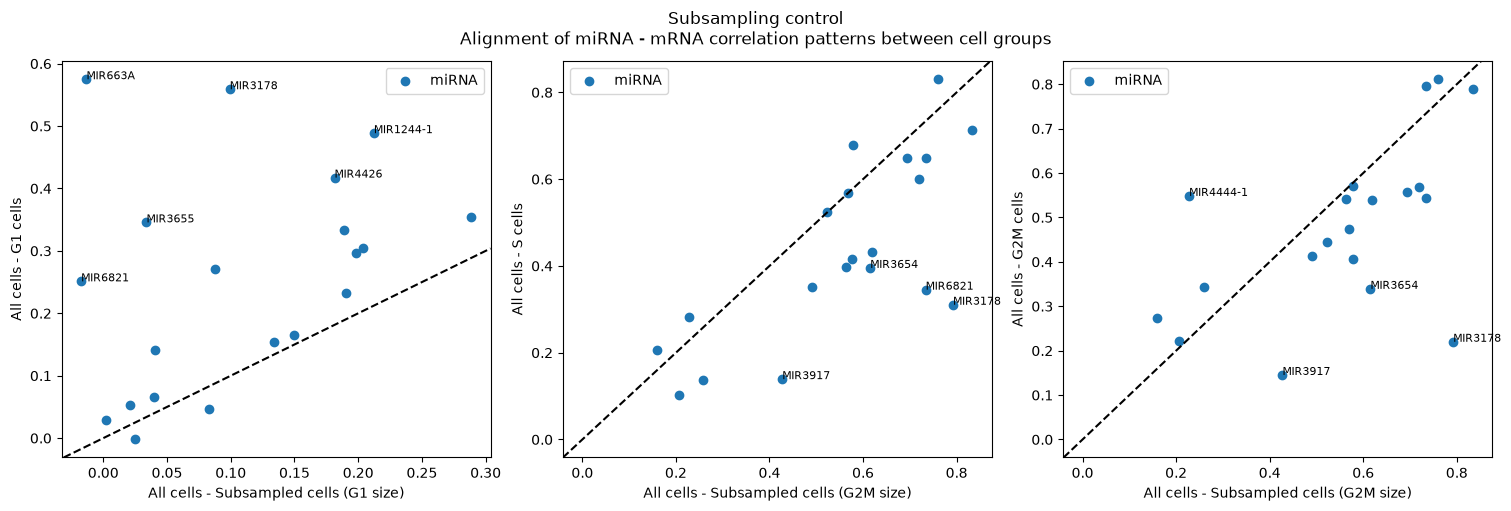

In [108]:
fig, axs = plt.subplots(1, 3, squeeze=False, figsize=(15, 5), constrained_layout=True)

tau = 0.2

axs[0, 0].scatter(alignment_table["All - N1"], alignment_table["All - G1"], label="miRNA")
for txt in alignment_table.index:
    x = alignment_table.loc[txt, "All - N1"]
    y = alignment_table.loc[txt, "All - G1"]
    if np.abs(x - y) > tau:
        axs[0, 0].annotate(txt, (x, y), fontsize=8)
axs[0, 0].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 0].set_xlabel("All cells - Subsampled cells (G1 size)")
axs[0, 0].set_ylabel("All cells - G1 cells")
axs[0, 0].legend()

axs[0, 1].scatter(alignment_table["All - N2"], alignment_table["All - S"], label="miRNA")
for txt in alignment_table.index:
    x = alignment_table.loc[txt, "All - N2"]
    y = alignment_table.loc[txt, "All - S"]
    if np.abs(x - y) > tau:
        axs[0, 1].annotate(txt, (x, y), fontsize=8)
axs[0, 1].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 1].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 1].set_ylabel("All cells - S cells")
axs[0, 1].legend()

axs[0, 2].scatter(alignment_table["All - N2"], alignment_table["All - G2M"], label="miRNA")
for txt in alignment_table.index:
    x = alignment_table.loc[txt, "All - N2"]
    y = alignment_table.loc[txt, "All - G2M"]
    if np.abs(x - y) > tau:
        axs[0, 2].annotate(txt, (x, y), fontsize=8)
axs[0, 2].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 2].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 2].set_ylabel("All cells - G2M cells")
axs[0, 2].legend()

fig.suptitle("Subsampling control\nAlignment of miRNA - mRNA correlation patterns between cell groups")
plt.show()

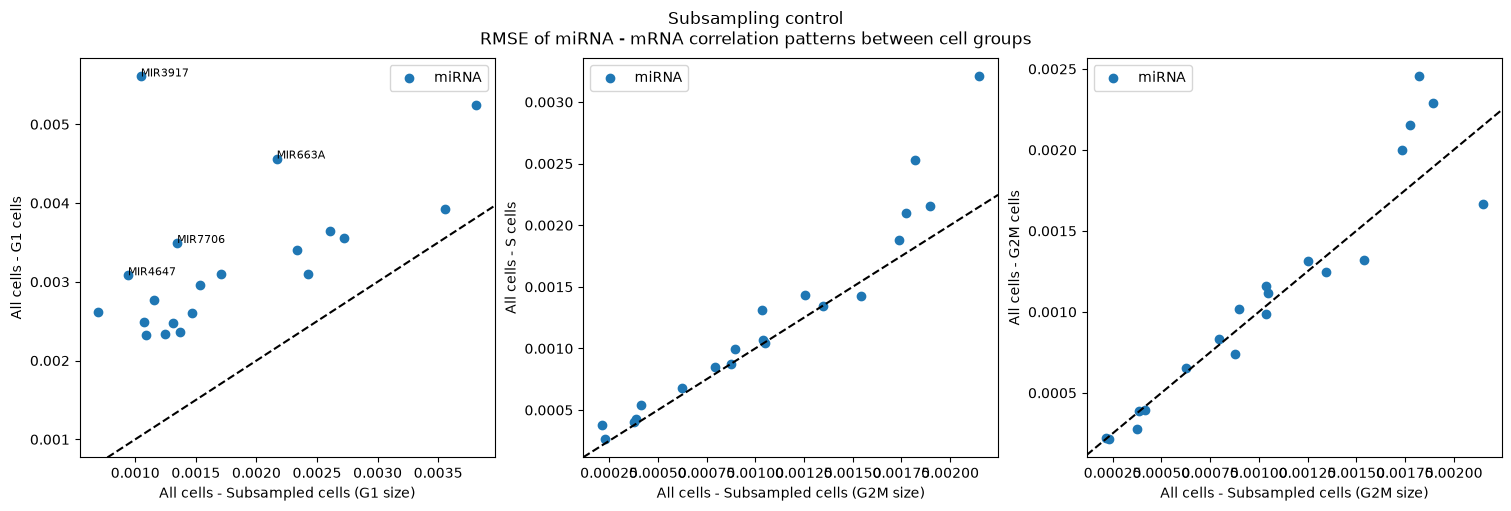

In [109]:
fig, axs = plt.subplots(1, 3, squeeze=False, figsize=(15, 5), constrained_layout=True)

tau = 0.002

axs[0, 0].scatter(RMSE_table["All - N1"], RMSE_table["All - G1"], label="miRNA")
for txt in RMSE_table.index:
    x = RMSE_table.loc[txt, "All - N1"]
    y = RMSE_table.loc[txt, "All - G1"]
    if np.abs(x - y) > tau:
        axs[0, 0].annotate(txt, (x, y), fontsize=8)
axs[0, 0].axline([0.001, 0.001], [0.002, 0.002], color="black", linestyle="--")
axs[0, 0].set_xlabel("All cells - Subsampled cells (G1 size)")
axs[0, 0].set_ylabel("All cells - G1 cells")
axs[0, 0].legend()

axs[0, 1].scatter(RMSE_table["All - N2"], RMSE_table["All - S"], label="miRNA")
for txt in RMSE_table.index:
    x = RMSE_table.loc[txt, "All - N2"]
    y = RMSE_table.loc[txt, "All - S"]
    if np.abs(x - y) > tau:
        axs[0, 1].annotate(txt, (x, y), fontsize=8)
axs[0, 1].axline([0.001, 0.001], [0.002, 0.002], color="black", linestyle="--")
axs[0, 1].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 1].set_ylabel("All cells - S cells")
axs[0, 1].legend()

axs[0, 2].scatter(RMSE_table["All - N2"], RMSE_table["All - G2M"], label="miRNA")
for txt in RMSE_table.index:
    x = RMSE_table.loc[txt, "All - N2"]
    y = RMSE_table.loc[txt, "All - G2M"]
    if np.abs(x - y) > tau:
        axs[0, 2].annotate(txt, (x, y), fontsize=8)
axs[0, 2].axline([0.001, 0.001], [0.002, 0.002], color="black", linestyle="--")
axs[0, 2].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 2].set_ylabel("All cells - G2M cells")
axs[0, 2].legend()

fig.suptitle("Subsampling control\nRMSE of miRNA - mRNA correlation patterns between cell groups")
plt.show()

### Sparsified

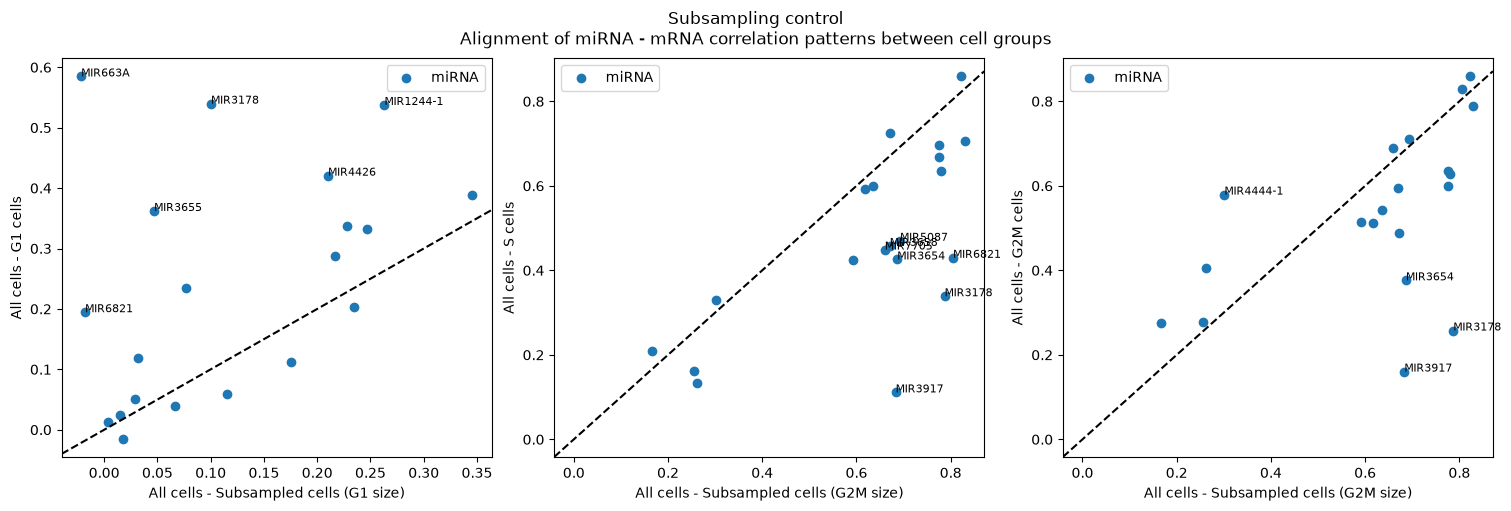

In [110]:
fig, axs = plt.subplots(1, 3, squeeze=False, figsize=(15, 5), constrained_layout=True)

tau = 0.2

axs[0, 0].scatter(alignment_table_sparse["All - N1"], alignment_table_sparse["All - G1"], label="miRNA")
for txt in alignment_table_sparse.index:
    x = alignment_table_sparse.loc[txt, "All - N1"]
    y = alignment_table_sparse.loc[txt, "All - G1"]
    if np.abs(x - y) > tau:
        axs[0, 0].annotate(txt, (x, y), fontsize=8)
axs[0, 0].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 0].set_xlabel("All cells - Subsampled cells (G1 size)")
axs[0, 0].set_ylabel("All cells - G1 cells")
axs[0, 0].legend()

axs[0, 1].scatter(alignment_table_sparse["All - N2"], alignment_table_sparse["All - S"], label="miRNA")
for txt in alignment_table_sparse.index:
    x = alignment_table_sparse.loc[txt, "All - N2"]
    y = alignment_table_sparse.loc[txt, "All - S"]
    if np.abs(x - y) > tau:
        axs[0, 1].annotate(txt, (x, y), fontsize=8)
axs[0, 1].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 1].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 1].set_ylabel("All cells - S cells")
axs[0, 1].legend()

axs[0, 2].scatter(alignment_table_sparse["All - N2"], alignment_table_sparse["All - G2M"], label="miRNA")
for txt in alignment_table_sparse.index:
    x = alignment_table_sparse.loc[txt, "All - N2"]
    y = alignment_table_sparse.loc[txt, "All - G2M"]
    if np.abs(x - y) > tau:
        axs[0, 2].annotate(txt, (x, y), fontsize=8)
axs[0, 2].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 2].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 2].set_ylabel("All cells - G2M cells")
axs[0, 2].legend()

fig.suptitle("Subsampling control\nAlignment of miRNA - mRNA correlation patterns between cell groups")
plt.show()

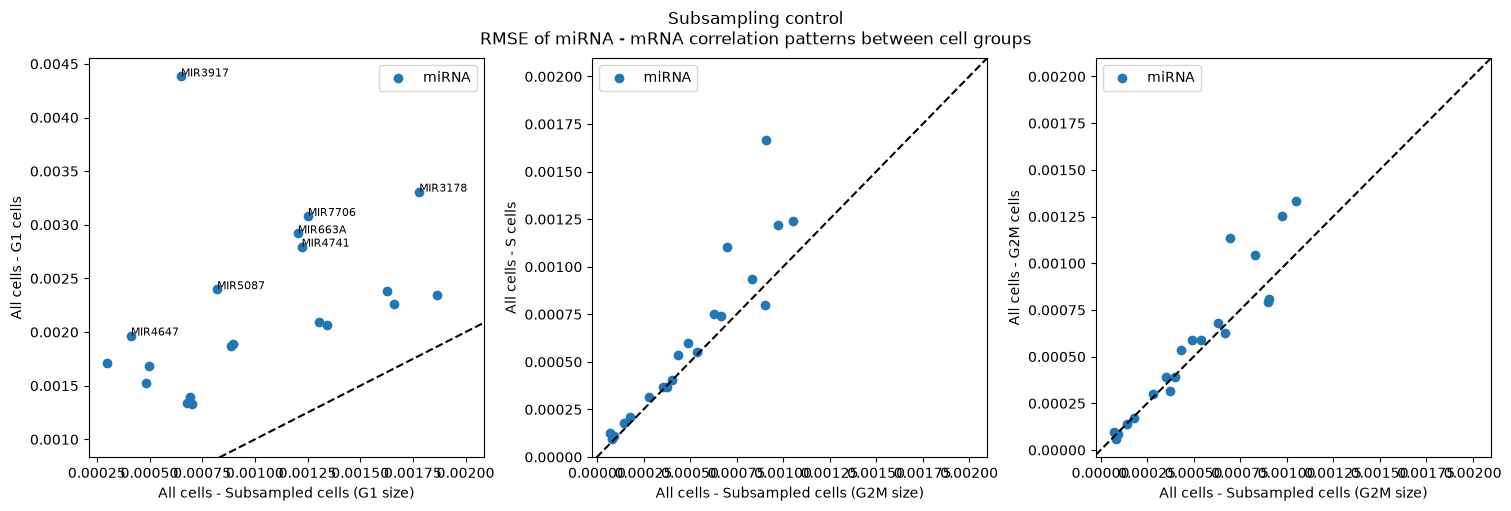

In [232]:
fig, axs = plt.subplots(1, 3, squeeze=False, figsize=(15, 5), constrained_layout=True)

tau = 0.0015

axs[0, 0].scatter(RMSE_table_sparse["All - N1"], RMSE_table_sparse["All - G1"], label="miRNA")
for txt in RMSE_table_sparse.index:
    x = RMSE_table_sparse.loc[txt, "All - N1"]
    y = RMSE_table_sparse.loc[txt, "All - G1"]
    if np.abs(x - y) > tau:
        axs[0, 0].annotate(txt, (x, y), fontsize=8)
axs[0, 0].axline([0.001, 0.001], [0.002, 0.002], color="black", linestyle="--")
axs[0, 0].set_xlabel("All cells - Subsampled cells (G1 size)")
axs[0, 0].set_ylabel("All cells - G1 cells")
axs[0, 0].legend()

axs[0, 1].scatter(RMSE_table_sparse["All - N2"], RMSE_table_sparse["All - S"], label="miRNA")
for txt in RMSE_table_sparse.index:
    x = RMSE_table_sparse.loc[txt, "All - N2"]
    y = RMSE_table_sparse.loc[txt, "All - S"]
    if np.abs(x - y) > tau:
        axs[0, 1].annotate(txt, (x, y), fontsize=8)
axs[0, 1].axline([0.001, 0.001], [0.002, 0.002], color="black", linestyle="--")
axs[0, 1].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 1].set_ylabel("All cells - S cells")
axs[0, 1].legend()

axs[0, 2].scatter(RMSE_table_sparse["All - N2"], RMSE_table_sparse["All - G2M"], label="miRNA")
for txt in RMSE_table_sparse.index:
    x = RMSE_table_sparse.loc[txt, "All - N2"]
    y = RMSE_table_sparse.loc[txt, "All - G2M"]
    if np.abs(x - y) > tau:
        axs[0, 2].annotate(txt, (x, y), fontsize=8)
axs[0, 2].axline([0.001, 0.001], [0.002, 0.002], color="black", linestyle="--")
axs[0, 2].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 2].set_ylabel("All cells - G2M cells")
axs[0, 2].legend()

fig.suptitle("Subsampling control\nRMSE of miRNA - mRNA correlation patterns between cell groups")
plt.show()

### Comparison

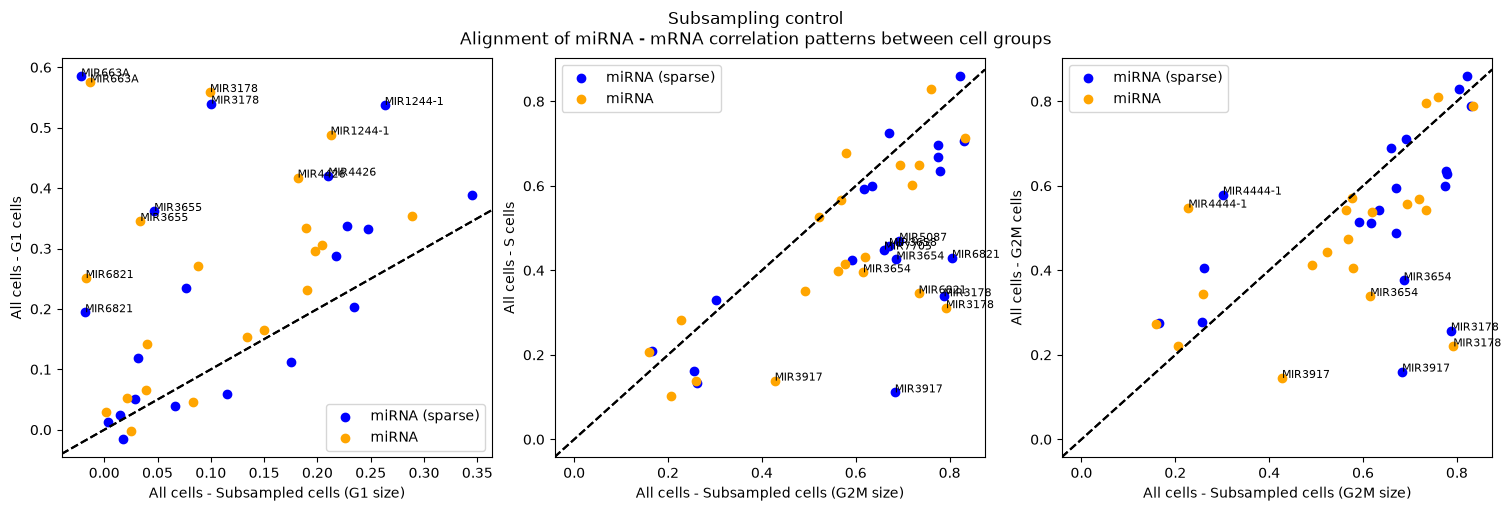

In [112]:
fig, axs = plt.subplots(1, 3, squeeze=False, figsize=(15, 5), constrained_layout=True)

tau = 0.2

axs[0, 0].scatter(alignment_table_sparse["All - N1"], alignment_table_sparse["All - G1"], label="miRNA (sparse)", color="blue")
for txt in alignment_table_sparse.index:
    x = alignment_table_sparse.loc[txt, "All - N1"]
    y = alignment_table_sparse.loc[txt, "All - G1"]
    if np.abs(x - y) > tau:
        axs[0, 0].annotate(txt, (x, y), fontsize=8)
axs[0, 0].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 0].set_xlabel("All cells - Subsampled cells (G1 size)")
axs[0, 0].set_ylabel("All cells - G1 cells")
axs[0, 0].legend()

axs[0, 1].scatter(alignment_table_sparse["All - N2"], alignment_table_sparse["All - S"], label="miRNA (sparse)", color="blue")
for txt in alignment_table_sparse.index:
    x = alignment_table_sparse.loc[txt, "All - N2"]
    y = alignment_table_sparse.loc[txt, "All - S"]
    if np.abs(x - y) > tau:
        axs[0, 1].annotate(txt, (x, y), fontsize=8)
axs[0, 1].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 1].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 1].set_ylabel("All cells - S cells")
axs[0, 1].legend()

axs[0, 2].scatter(alignment_table_sparse["All - N2"], alignment_table_sparse["All - G2M"], label="miRNA (sparse)", color="blue")
for txt in alignment_table_sparse.index:
    x = alignment_table_sparse.loc[txt, "All - N2"]
    y = alignment_table_sparse.loc[txt, "All - G2M"]
    if np.abs(x - y) > tau:
        axs[0, 2].annotate(txt, (x, y), fontsize=8)
axs[0, 2].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 2].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 2].set_ylabel("All cells - G2M cells")
axs[0, 2].legend()

axs[0, 0].scatter(alignment_table["All - N1"], alignment_table["All - G1"], label="miRNA", color="orange")
for txt in alignment_table.index:
    x = alignment_table.loc[txt, "All - N1"]
    y = alignment_table.loc[txt, "All - G1"]
    if np.abs(x - y) > tau:
        axs[0, 0].annotate(txt, (x, y), fontsize=8)
axs[0, 0].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 0].set_xlabel("All cells - Subsampled cells (G1 size)")
axs[0, 0].set_ylabel("All cells - G1 cells")
axs[0, 0].legend()

axs[0, 1].scatter(alignment_table["All - N2"], alignment_table["All - S"], label="miRNA", color="orange")
for txt in alignment_table.index:
    x = alignment_table.loc[txt, "All - N2"]
    y = alignment_table.loc[txt, "All - S"]
    if np.abs(x - y) > tau:
        axs[0, 1].annotate(txt, (x, y), fontsize=8)
axs[0, 1].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 1].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 1].set_ylabel("All cells - S cells")
axs[0, 1].legend()

axs[0, 2].scatter(alignment_table["All - N2"], alignment_table["All - G2M"], label="miRNA", color="orange")
for txt in alignment_table.index:
    x = alignment_table.loc[txt, "All - N2"]
    y = alignment_table.loc[txt, "All - G2M"]
    if np.abs(x - y) > tau:
        axs[0, 2].annotate(txt, (x, y), fontsize=8)
axs[0, 2].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 2].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 2].set_ylabel("All cells - G2M cells")
axs[0, 2].legend()

fig.suptitle("Subsampling control\nAlignment of miRNA - mRNA correlation patterns between cell groups")
plt.show()

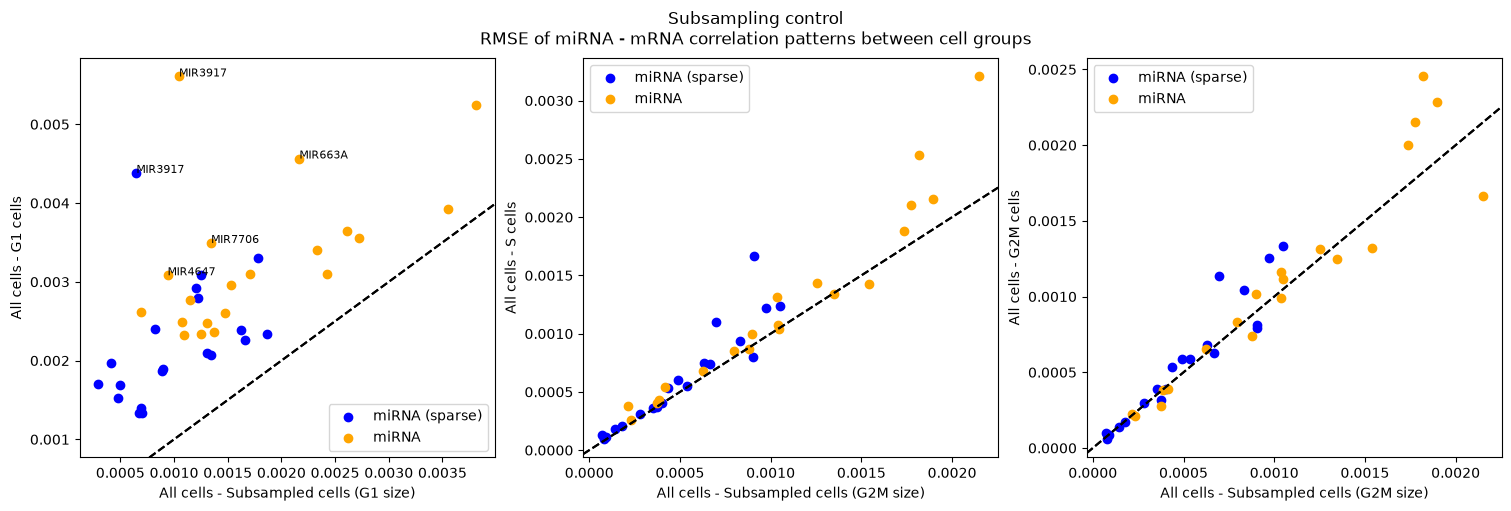

In [113]:
fig, axs = plt.subplots(1, 3, squeeze=False, figsize=(15, 5), constrained_layout=True)

tau = 0.002

axs[0, 0].scatter(RMSE_table_sparse["All - N1"], RMSE_table_sparse["All - G1"], label="miRNA (sparse)", color="blue")
for txt in RMSE_table_sparse.index:
    x = RMSE_table_sparse.loc[txt, "All - N1"]
    y = RMSE_table_sparse.loc[txt, "All - G1"]
    if np.abs(x - y) > tau:
        axs[0, 0].annotate(txt, (x, y), fontsize=8)
axs[0, 0].axline([0.001, 0.001], [0.002, 0.002], color="black", linestyle="--")
axs[0, 0].set_xlabel("All cells - Subsampled cells (G1 size)")
axs[0, 0].set_ylabel("All cells - G1 cells")
axs[0, 0].legend()

axs[0, 1].scatter(RMSE_table_sparse["All - N2"], RMSE_table_sparse["All - S"], label="miRNA (sparse)", color="blue")
for txt in RMSE_table_sparse.index:
    x = RMSE_table_sparse.loc[txt, "All - N2"]
    y = RMSE_table_sparse.loc[txt, "All - S"]
    if np.abs(x - y) > tau:
        axs[0, 1].annotate(txt, (x, y), fontsize=8)
axs[0, 1].axline([0.001, 0.001], [0.002, 0.002], color="black", linestyle="--")
axs[0, 1].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 1].set_ylabel("All cells - S cells")
axs[0, 1].legend()

axs[0, 2].scatter(RMSE_table_sparse["All - N2"], RMSE_table_sparse["All - G2M"], label="miRNA (sparse)", color="blue")
for txt in RMSE_table_sparse.index:
    x = RMSE_table_sparse.loc[txt, "All - N2"]
    y = RMSE_table_sparse.loc[txt, "All - G2M"]
    if np.abs(x - y) > tau:
        axs[0, 2].annotate(txt, (x, y), fontsize=8)
axs[0, 2].axline([0.001, 0.001], [0.002, 0.002], color="black", linestyle="--")
axs[0, 2].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 2].set_ylabel("All cells - G2M cells")
axs[0, 2].legend()

axs[0, 0].scatter(RMSE_table["All - N1"], RMSE_table["All - G1"], label="miRNA", color="orange")
for txt in RMSE_table.index:
    x = RMSE_table.loc[txt, "All - N1"]
    y = RMSE_table.loc[txt, "All - G1"]
    if np.abs(x - y) > tau:
        axs[0, 0].annotate(txt, (x, y), fontsize=8)
axs[0, 0].axline([0.001, 0.001], [0.002, 0.002], color="black", linestyle="--")
axs[0, 0].set_xlabel("All cells - Subsampled cells (G1 size)")
axs[0, 0].set_ylabel("All cells - G1 cells")
axs[0, 0].legend()

axs[0, 1].scatter(RMSE_table["All - N2"], RMSE_table["All - S"], label="miRNA", color="orange")
for txt in RMSE_table.index:
    x = RMSE_table.loc[txt, "All - N2"]
    y = RMSE_table.loc[txt, "All - S"]
    if np.abs(x - y) > tau:
        axs[0, 1].annotate(txt, (x, y), fontsize=8)
axs[0, 1].axline([0.001, 0.001], [0.002, 0.002], color="black", linestyle="--")
axs[0, 1].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 1].set_ylabel("All cells - S cells")
axs[0, 1].legend()

axs[0, 2].scatter(RMSE_table["All - N2"], RMSE_table["All - G2M"], label="miRNA", color="orange")
for txt in RMSE_table.index:
    x = RMSE_table.loc[txt, "All - N2"]
    y = RMSE_table.loc[txt, "All - G2M"]
    if np.abs(x - y) > tau:
        axs[0, 2].annotate(txt, (x, y), fontsize=8)
axs[0, 2].axline([0.001, 0.001], [0.002, 0.002], color="black", linestyle="--")
axs[0, 2].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 2].set_ylabel("All cells - G2M cells")
axs[0, 2].legend()

fig.suptitle("Subsampling control\nRMSE of miRNA - mRNA correlation patterns between cell groups")
plt.show()

## To and Between Phases

### Midpoint

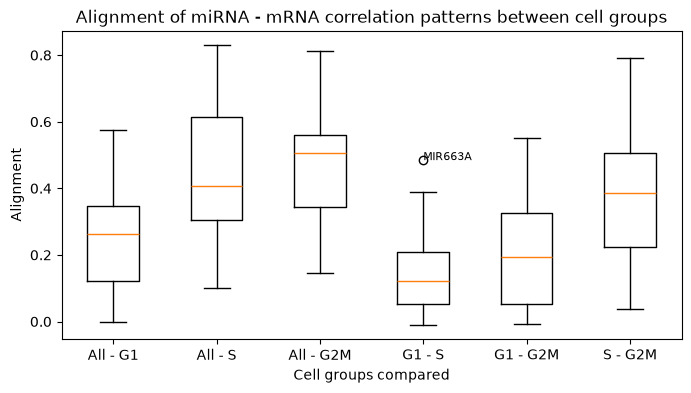

In [114]:
fig, axs = plt.subplots(figsize=(8, 4))
df = alignment_table[["All - G1", "All - S", "All - G2M", "G1 - S", "G1 - G2M", "S - G2M"]]
bp = axs.boxplot(df);
for i, flier in enumerate(bp['fliers']):
    pos, vals = flier.get_data()
    col = df.iloc[:, i]
    for val in vals:
        miRNA = col[col == val].index.tolist()[0]
        plt.annotate(miRNA, (i + 1, val), fontsize=8)
axs.set_xticks(range(1, df.shape[1] + 1))
axs.set_xticklabels(df.columns)
axs.set_ylabel("Alignment")
axs.set_xlabel("Cell groups compared")
axs.set_title("Alignment of miRNA - mRNA correlation patterns between cell groups")
plt.show()

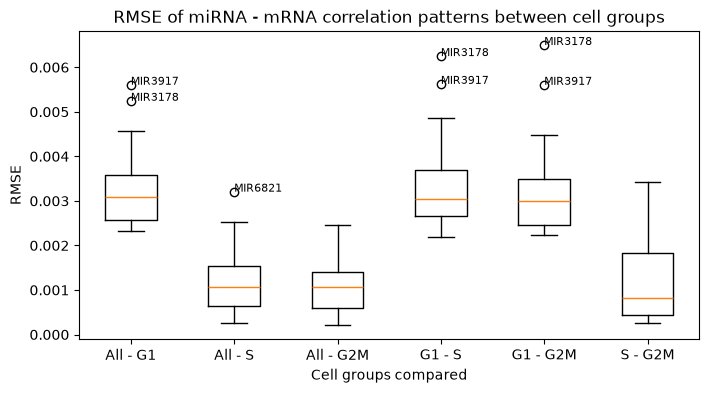

In [115]:
fig, axs = plt.subplots(figsize=(8, 4))
df = RMSE_table[["All - G1", "All - S", "All - G2M", "G1 - S", "G1 - G2M", "S - G2M"]]
bp = axs.boxplot(df);
for i, flier in enumerate(bp['fliers']):
    pos, vals = flier.get_data()
    col = df.iloc[:, i]
    for val in vals:
        miRNA = col[col == val].index.tolist()[0]
        plt.annotate(miRNA, (i + 1, val), fontsize=8)
axs.set_xticks(range(1, df.shape[1] + 1))
axs.set_xticklabels(df.columns)
axs.set_ylabel("RMSE")
axs.set_xlabel("Cell groups compared")
axs.set_title("RMSE of miRNA - mRNA correlation patterns between cell groups")
plt.show()

### Sparsified

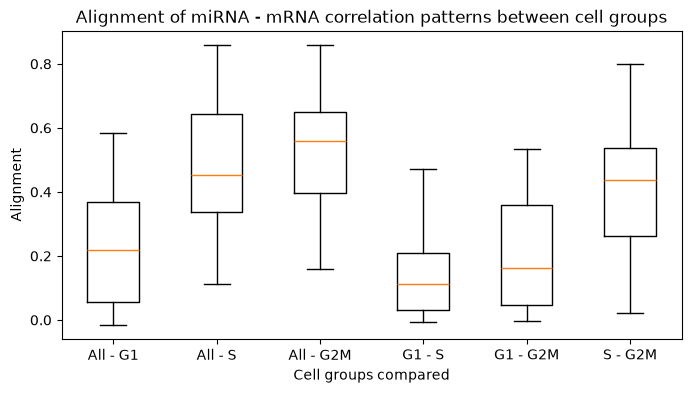

In [116]:
fig, axs = plt.subplots(figsize=(8, 4))
df = alignment_table_sparse[["All - G1", "All - S", "All - G2M", "G1 - S", "G1 - G2M", "S - G2M"]]
bp = axs.boxplot(df);
for i, flier in enumerate(bp['fliers']):
    pos, vals = flier.get_data()
    col = df.iloc[:, i]
    for val in vals:
        miRNA = col[col == val].index.tolist()[0]
        plt.annotate(miRNA, (i + 1, val), fontsize=8)
axs.set_xticks(range(1, df.shape[1] + 1))
axs.set_xticklabels(df.columns)
axs.set_ylabel("Alignment")
axs.set_xlabel("Cell groups compared")
axs.set_title("Alignment of miRNA - mRNA correlation patterns between cell groups")
plt.show()

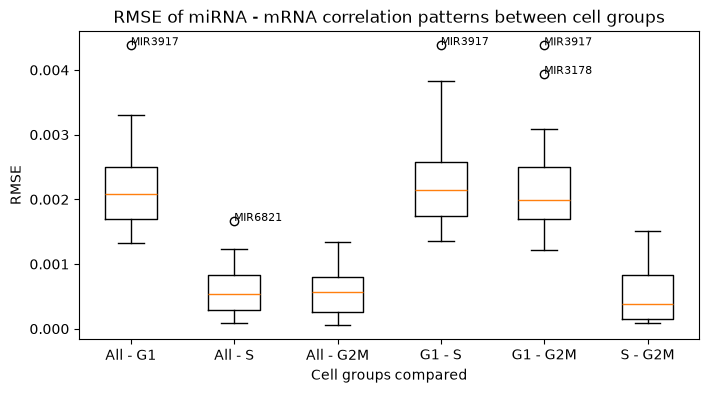

In [117]:
fig, axs = plt.subplots(figsize=(8, 4))
df = RMSE_table_sparse[["All - G1", "All - S", "All - G2M", "G1 - S", "G1 - G2M", "S - G2M"]]
bp = axs.boxplot(df);
for i, flier in enumerate(bp['fliers']):
    pos, vals = flier.get_data()
    col = df.iloc[:, i]
    for val in vals:
        miRNA = col[col == val].index.tolist()[0]
        plt.annotate(miRNA, (i + 1, val), fontsize=8)
axs.set_xticks(range(1, df.shape[1] + 1))
axs.set_xticklabels(df.columns)
axs.set_ylabel("RMSE")
axs.set_xlabel("Cell groups compared")
axs.set_title("RMSE of miRNA - mRNA correlation patterns between cell groups")
plt.show()

## To and Between Subsample controls

### Midpoint

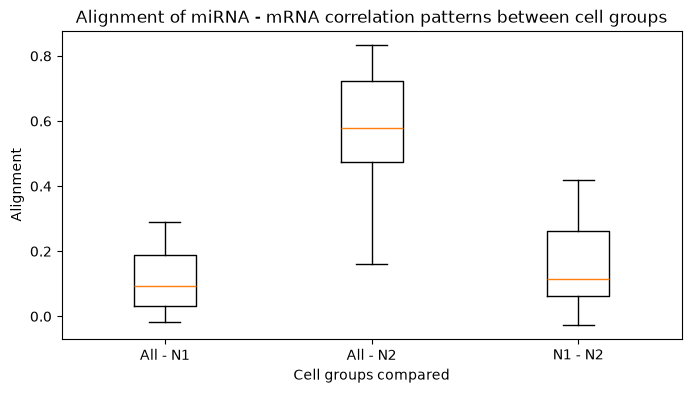

In [118]:
fig, axs = plt.subplots(figsize=(8, 4))
df = alignment_table[["All - N1", "All - N2", "N1 - N2"]]
bp = axs.boxplot(df);
for i, flier in enumerate(bp['fliers']):
    pos, vals = flier.get_data()
    col = df.iloc[:, i]
    for val in vals:
        miRNA = col[col == val].index.tolist()[0]
        plt.annotate(miRNA, (i + 1, val), fontsize=8)
axs.set_xticks(range(1, df.shape[1] + 1))
axs.set_xticklabels(df.columns)
axs.set_ylabel("Alignment")
axs.set_xlabel("Cell groups compared")
axs.set_title("Alignment of miRNA - mRNA correlation patterns between cell groups")
plt.show()

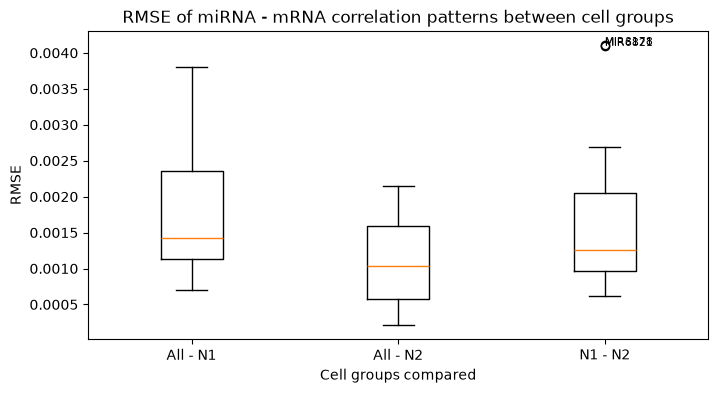

In [119]:
fig, axs = plt.subplots(figsize=(8, 4))
df = RMSE_table[["All - N1", "All - N2", "N1 - N2"]]
bp = axs.boxplot(df);
for i, flier in enumerate(bp['fliers']):
    pos, vals = flier.get_data()
    col = df.iloc[:, i]
    for val in vals:
        miRNA = col[col == val].index.tolist()[0]
        plt.annotate(miRNA, (i + 1, val), fontsize=8)
axs.set_xticks(range(1, df.shape[1] + 1))
axs.set_xticklabels(df.columns)
axs.set_ylabel("RMSE")
axs.set_xlabel("Cell groups compared")
axs.set_title("RMSE of miRNA - mRNA correlation patterns between cell groups")
plt.show()

### Sparsified

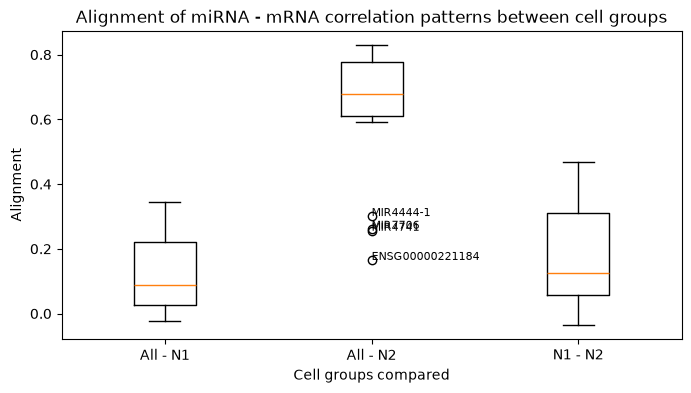

In [120]:
fig, axs = plt.subplots(figsize=(8, 4))
df = alignment_table_sparse[["All - N1", "All - N2", "N1 - N2"]]
bp = axs.boxplot(df);
for i, flier in enumerate(bp['fliers']):
    pos, vals = flier.get_data()
    col = df.iloc[:, i]
    for val in vals:
        miRNA = col[col == val].index.tolist()[0]
        plt.annotate(miRNA, (i + 1, val), fontsize=8)
axs.set_xticks(range(1, df.shape[1] + 1))
axs.set_xticklabels(df.columns)
axs.set_ylabel("Alignment")
axs.set_xlabel("Cell groups compared")
axs.set_title("Alignment of miRNA - mRNA correlation patterns between cell groups")
plt.show()

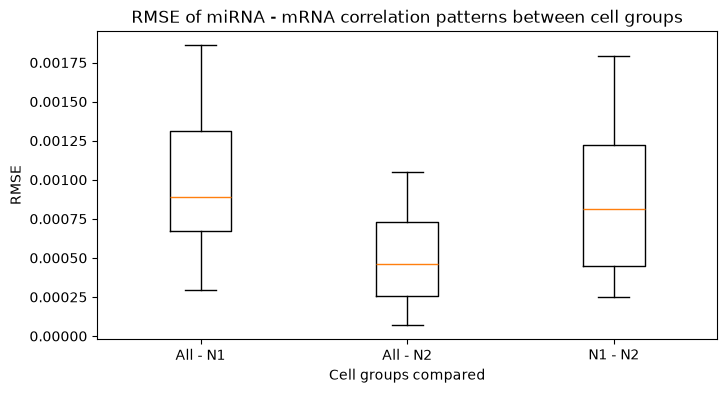

In [121]:
fig, axs = plt.subplots(figsize=(8, 4))
df = RMSE_table_sparse[["All - N1", "All - N2", "N1 - N2"]]
bp = axs.boxplot(df);
for i, flier in enumerate(bp['fliers']):
    pos, vals = flier.get_data()
    col = df.iloc[:, i]
    for val in vals:
        miRNA = col[col == val].index.tolist()[0]
        plt.annotate(miRNA, (i + 1, val), fontsize=8)
axs.set_xticks(range(1, df.shape[1] + 1))
axs.set_xticklabels(df.columns)
axs.set_ylabel("RMSE")
axs.set_xlabel("Cell groups compared")
axs.set_title("RMSE of miRNA - mRNA correlation patterns between cell groups")
plt.show()

## Outliers

In [122]:
tau = 0.1
mask_1 = (np.abs(alignment_table_sparse["All - G1"] - alignment_table_sparse["All - N1"]) > tau).values
mask_2 = (np.abs(alignment_table_sparse["All - S"] - alignment_table_sparse["All - N2"]) > tau).values
mask_3 = (np.abs(alignment_table_sparse["All - G2M"] - alignment_table_sparse["All - N2"]) > tau).values
miRNA_outliers = np.array(miRNA_names)[mask_1 & mask_2 & mask_3]
miRNA_outliers

array(['MIR4426', 'MIR3655', 'MIR3178'], dtype='<U15')

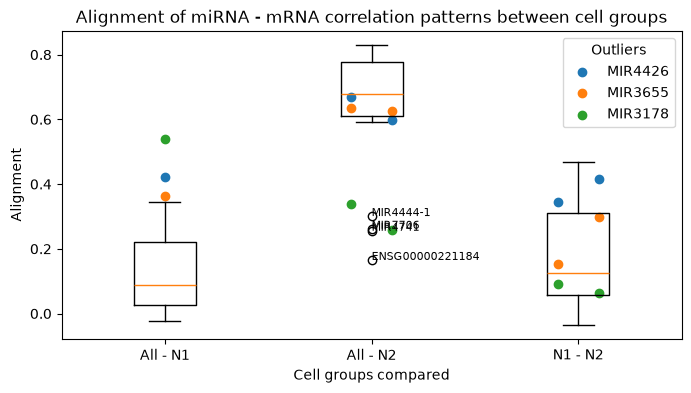

In [123]:
fig, axs = plt.subplots(figsize=(8, 4))
df = alignment_table_sparse[["All - N1", "All - N2", "N1 - N2"]]
bp = axs.boxplot(df);
for i, flier in enumerate(bp['fliers']):
    pos, vals = flier.get_data()
    col = df.iloc[:, i]
    for val in vals:
        miRNA = col[col == val].index.tolist()[0]
        plt.annotate(miRNA, (i + 1, val), fontsize=8)
for i, miRNA_outlier in enumerate(miRNA_outliers):
    axs.scatter(
        [1, 1.9, 2.1, 2.9, 3.1],
        [
            alignment_table_sparse.loc[miRNA_outlier, "All - G1"],
            alignment_table_sparse.loc[miRNA_outlier, "All - S"],
            alignment_table_sparse.loc[miRNA_outlier, "All - G2M"],
            alignment_table_sparse.loc[miRNA_outlier, "G1 - S"],
            alignment_table_sparse.loc[miRNA_outlier, "G1 - G2M"],
        ],
        color=f"C{i}",
        label=miRNA_outlier
    )
axs.set_xticks(range(1, df.shape[1] + 1))
axs.set_xticklabels(df.columns)
axs.set_ylabel("Alignment")
axs.set_xlabel("Cell groups compared")
axs.set_title("Alignment of miRNA - mRNA correlation patterns between cell groups")
axs.legend(title="Outliers")
plt.show()

In [124]:
tau = 0.00025
mask_1 = (np.abs(RMSE_table_sparse["All - G1"] - RMSE_table_sparse["All - N1"]) > tau).values
mask_2 = (np.abs(RMSE_table_sparse["All - S"] - RMSE_table_sparse["All - N2"]) > tau).values
mask_3 = (np.abs(RMSE_table_sparse["All - G2M"] - RMSE_table_sparse["All - N2"]) > tau).values
miRNA_outliers = np.array(miRNA_names)[mask_1 & mask_2 & mask_3]
miRNA_outliers

array(['MIR3178'], dtype='<U15')

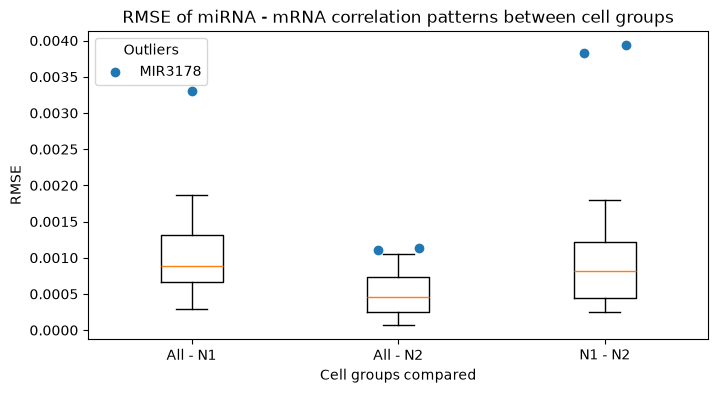

In [125]:
fig, axs = plt.subplots(figsize=(8, 4))
df = RMSE_table_sparse[["All - N1", "All - N2", "N1 - N2"]]
bp = axs.boxplot(df);
for i, flier in enumerate(bp['fliers']):
    pos, vals = flier.get_data()
    col = df.iloc[:, i]
    for val in vals:
        miRNA = col[col == val].index.tolist()[0]
        plt.annotate(miRNA, (i + 1, val), fontsize=8)
for i, miRNA_outlier in enumerate(miRNA_outliers):
    axs.scatter(
        [1, 1.9, 2.1, 2.9, 3.1],
        [
            RMSE_table_sparse.loc[miRNA_outlier, "All - G1"],
            RMSE_table_sparse.loc[miRNA_outlier, "All - S"],
            RMSE_table_sparse.loc[miRNA_outlier, "All - G2M"],
            RMSE_table_sparse.loc[miRNA_outlier, "G1 - S"],
            RMSE_table_sparse.loc[miRNA_outlier, "G1 - G2M"],
        ],
        color=f"C{i}",
        label=miRNA_outlier
    )
axs.set_xticks(range(1, df.shape[1] + 1))
axs.set_xticklabels(df.columns)
axs.set_ylabel("RMSE")
axs.set_xlabel("Cell groups compared")
axs.set_title("RMSE of miRNA - mRNA correlation patterns between cell groups")
axs.legend(title="Outliers")
plt.show()

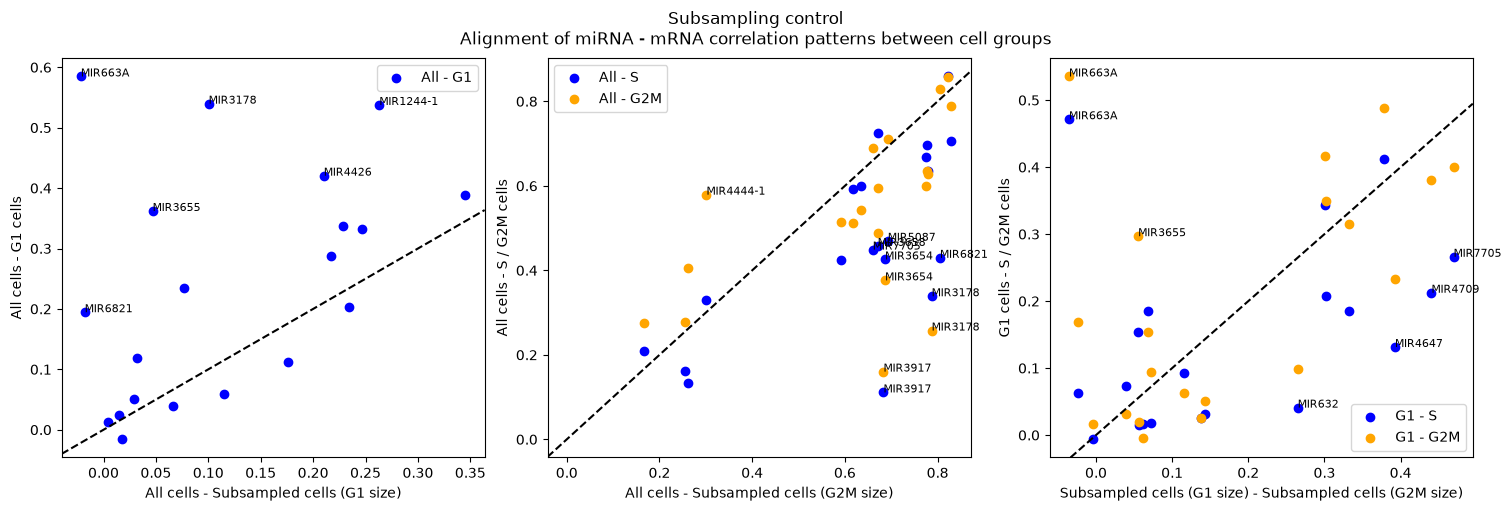

In [126]:
fig, axs = plt.subplots(1, 3, squeeze=False, figsize=(15, 5), constrained_layout=True)

tau = 0.2

axs[0, 0].scatter(alignment_table_sparse["All - N1"], alignment_table_sparse["All - G1"], label="All - G1", color="blue")
for txt in alignment_table_sparse.index:
    x = alignment_table_sparse.loc[txt, "All - N1"]
    y = alignment_table_sparse.loc[txt, "All - G1"]
    if np.abs(x - y) > tau:
        axs[0, 0].annotate(txt, (x, y), fontsize=8)
axs[0, 0].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 0].set_xlabel("All cells - Subsampled cells (G1 size)")
axs[0, 0].set_ylabel("All cells - G1 cells")
axs[0, 0].legend()

axs[0, 1].scatter(alignment_table_sparse["All - N2"], alignment_table_sparse["All - S"], label="All - S", color="blue")
for txt in alignment_table_sparse.index:
    x = alignment_table_sparse.loc[txt, "All - N2"]
    y = alignment_table_sparse.loc[txt, "All - S"]
    if np.abs(x - y) > tau:
        axs[0, 1].annotate(txt, (x, y), fontsize=8)
axs[0, 1].scatter(alignment_table_sparse["All - N2"], alignment_table_sparse["All - G2M"], label="All - G2M", color="orange")
for txt in alignment_table_sparse.index:
    x = alignment_table_sparse.loc[txt, "All - N2"]
    y = alignment_table_sparse.loc[txt, "All - G2M"]
    if np.abs(x - y) > tau:
        axs[0, 1].annotate(txt, (x, y), fontsize=8)
axs[0, 1].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 1].set_xlabel("All cells - Subsampled cells (G2M size)")
axs[0, 1].set_ylabel("All cells - S / G2M cells")
axs[0, 1].legend()

axs[0, 2].scatter(alignment_table_sparse["N1 - N2"], alignment_table_sparse["G1 - S"], label="G1 - S", color="blue")
for txt in alignment_table_sparse.index:
    x = alignment_table_sparse.loc[txt, "N1 - N2"]
    y = alignment_table_sparse.loc[txt, "G1 - S"]
    if np.abs(x - y) > tau:
        axs[0, 2].annotate(txt, (x, y), fontsize=8)
axs[0, 2].scatter(alignment_table_sparse["N1 - N2"], alignment_table_sparse["G1 - G2M"], label="G1 - G2M", color="orange")
for txt in alignment_table_sparse.index:
    x = alignment_table_sparse.loc[txt, "N1 - N2"]
    y = alignment_table_sparse.loc[txt, "G1 - G2M"]
    if np.abs(x - y) > tau:
        axs[0, 2].annotate(txt, (x, y), fontsize=8)
axs[0, 2].axline([0, 0], [0.1, 0.1], color="black", linestyle="--")
axs[0, 2].set_xlabel("Subsampled cells (G1 size) - Subsampled cells (G2M size)")
axs[0, 2].set_ylabel("G1 cells - S / G2M cells")
axs[0, 2].legend()

fig.suptitle("Subsampling control\nAlignment of miRNA - mRNA correlation patterns between cell groups")
plt.show()

## Observed & Recovered Violin: Cell cycle vs Subsampling control

In [219]:
miRNA_names = adata_miRNA.var['GeneName'].tolist()
miRNA_names

['MIR3917',
 'MIR5087',
 'MIR3658',
 'MIR4426',
 'MIR4444-1',
 'MIR1244-1',
 'MIR3655',
 'MIR4647',
 'MIR3654',
 'MIR7705',
 'ENSG00000221184',
 'MIR3652',
 'MIR4709',
 'MIR7706',
 'MIR3178',
 'MIR632',
 'MIR4741',
 'MIR1181',
 'MIR663A',
 'MIR6821']

In [220]:
all_corr_HR = MF_int_df[[f"{miRNA}_All_HAR_mid" for miRNA in miRNA_names]].values.flatten()
all_mask = ~np.isnan(all_corr_HR)
all_corr_HR = all_corr_HR[all_mask]

G1_corr_HR = MF_int_df[[f"{miRNA}_G1_HAR_mid" for miRNA in miRNA_names]].values.flatten()
G1_mask = ~np.isnan(G1_corr_HR)
G1_corr_HR = G1_corr_HR[G1_mask]

S_corr_HR = MF_int_df[[f"{miRNA}_S_HAR_mid" for miRNA in miRNA_names]].values.flatten()
S_mask = ~np.isnan(S_corr_HR)
S_corr_HR = S_corr_HR[S_mask]

G2M_corr_HR = MF_int_df[[f"{miRNA}_G2M_HAR_mid" for miRNA in miRNA_names]].values.flatten()
G2M_mask = ~np.isnan(G2M_corr_HR)
G2M_corr_HR = G2M_corr_HR[G2M_mask]

In [221]:
all_corr_OB = corr_df[[f"{miRNA}_All_OB" for miRNA in miRNA_names]].values.flatten()
all_corr_OB_int = all_corr_OB[all_mask]

G1_corr_OB = corr_df[[f"{miRNA}_G1_OB" for miRNA in miRNA_names]].values.flatten()
G1_corr_OB_int = G1_corr_OB[G1_mask]

S_corr_OB = corr_df[[f"{miRNA}_S_OB" for miRNA in miRNA_names]].values.flatten()
S_corr_OB_int = S_corr_OB[S_mask]

G2M_corr_OB = corr_df[[f"{miRNA}_G2M_OB" for miRNA in miRNA_names]].values.flatten()
G2M_corr_OB_int = G2M_corr_OB[G2M_mask]

In [222]:
all_corr_HR = MF_int_df[[f"{miRNA}_All_HAR_mid" for miRNA in miRNA_names]].values.flatten()
all_mask = ~np.isnan(all_corr_HR)
all_corr_HR = all_corr_HR[all_mask]

N1_corr_HR = MF_int_df[[f"{miRNA}_N1_HAR_mid" for miRNA in miRNA_names]].values.flatten()
N1_mask = ~np.isnan(N1_corr_HR)
N1_corr_HR = N1_corr_HR[N1_mask]

N2_corr_HR = MF_int_df[[f"{miRNA}_N2_HAR_mid" for miRNA in miRNA_names]].values.flatten()
N2_mask = ~np.isnan(N2_corr_HR)
N2_corr_HR = N2_corr_HR[N2_mask]

In [223]:
all_corr_OB = corr_df[[f"{miRNA}_All_OB" for miRNA in miRNA_names]].values.flatten()
all_corr_OB_int = all_corr_OB[all_mask]

N1_corr_OB = corr_df[[f"{miRNA}_N1_OB" for miRNA in miRNA_names]].values.flatten()
N1_corr_OB_int = N1_corr_OB[N1_mask]

N2_corr_OB = corr_df[[f"{miRNA}_N2_OB" for miRNA in miRNA_names]].values.flatten()
N2_corr_OB_int = N2_corr_OB[N2_mask]

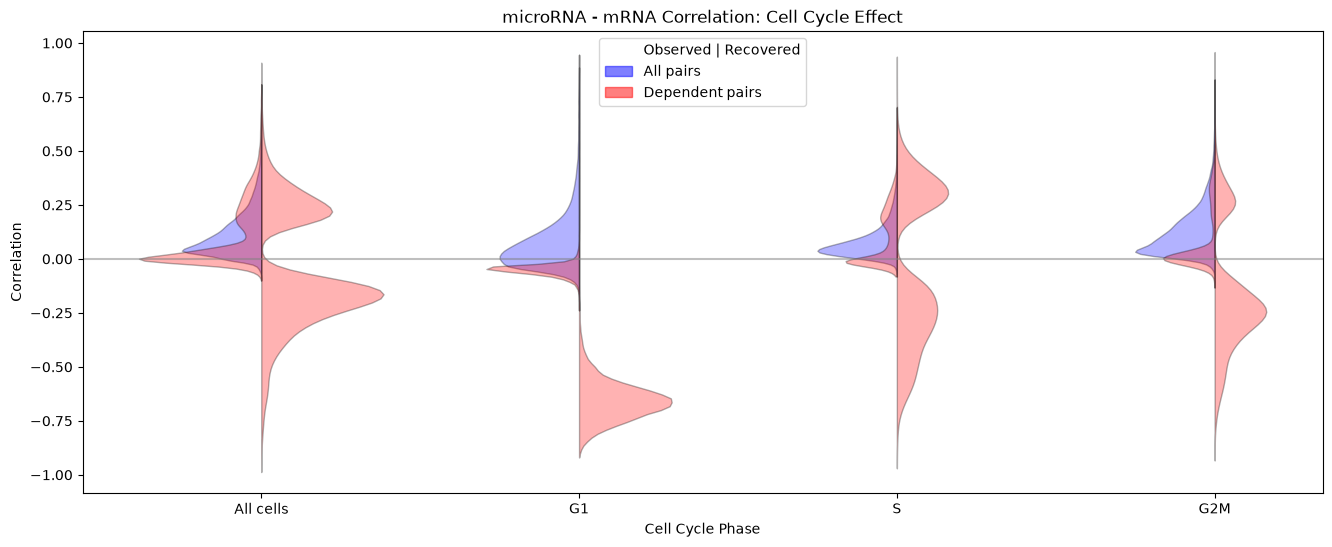

In [224]:
fig, axs = plt.subplots(figsize=(16, 6))

# width scaling
k = 2

# all observed
plot_data_list = [
    all_corr_OB,
    G1_corr_OB,
    S_corr_OB,
    G2M_corr_OB
]
total_size = sum([dt.size for dt in plot_data_list])
for i, plot_data in enumerate(plot_data_list):
    vp = axs.violinplot(
        dataset=plot_data,
        positions=[i],
        showextrema=False,
        side="low",
        widths=k * (plot_data.size / total_size)
    )
    vp['bodies'][0].set_facecolor("blue")
    vp['bodies'][0].set_edgecolor("black")

# interacting observed
plot_data_list = [
    all_corr_OB_int,
    G1_corr_OB_int,
    S_corr_OB_int,
    G2M_corr_OB_int
]
total_size = sum([dt.size for dt in plot_data_list])
for i, plot_data in enumerate(plot_data_list):
    vp = axs.violinplot(
        dataset=plot_data,
        positions=[i],
        showextrema=False,
        side="low",
        widths=k * (plot_data.size / total_size)
    )
    vp['bodies'][0].set_facecolor("red")
    vp['bodies'][0].set_edgecolor("black")

# interacting recovered
plot_data_list = [
    all_corr_HR,
    G1_corr_HR,
    S_corr_HR,
    G2M_corr_HR
]
total_size = sum([dt.size for dt in plot_data_list])
for i, plot_data in enumerate(plot_data_list):
    vp = axs.violinplot(
        dataset=plot_data,
        positions=[i],
        showextrema=False,
        side="high",
        widths=k * (plot_data.size / total_size)
    )
    vp['bodies'][0].set_facecolor("red")
    vp['bodies'][0].set_edgecolor("black")


plt.axvspan(0, 0, 0, 0, color="white", label="Observed | Recovered")
plt.axvspan(0, 0, 0, 0, alpha=0.5, color="blue", label="All pairs")
plt.axvspan(0, 0, 0, 0, alpha=0.5, color="red", label="Dependent pairs")
axs.legend()

axs.axhline(0, color="grey", alpha=0.5)
axs.set_xticks([0, 1, 2, 3])
axs.set_xticklabels(["All cells", "G1", "S", "G2M"])
axs.set_xlabel("Cell Cycle Phase")
axs.set_ylabel(f"Correlation")
axs.set_title("microRNA - mRNA Correlation: Cell Cycle Effect")
plt.show()

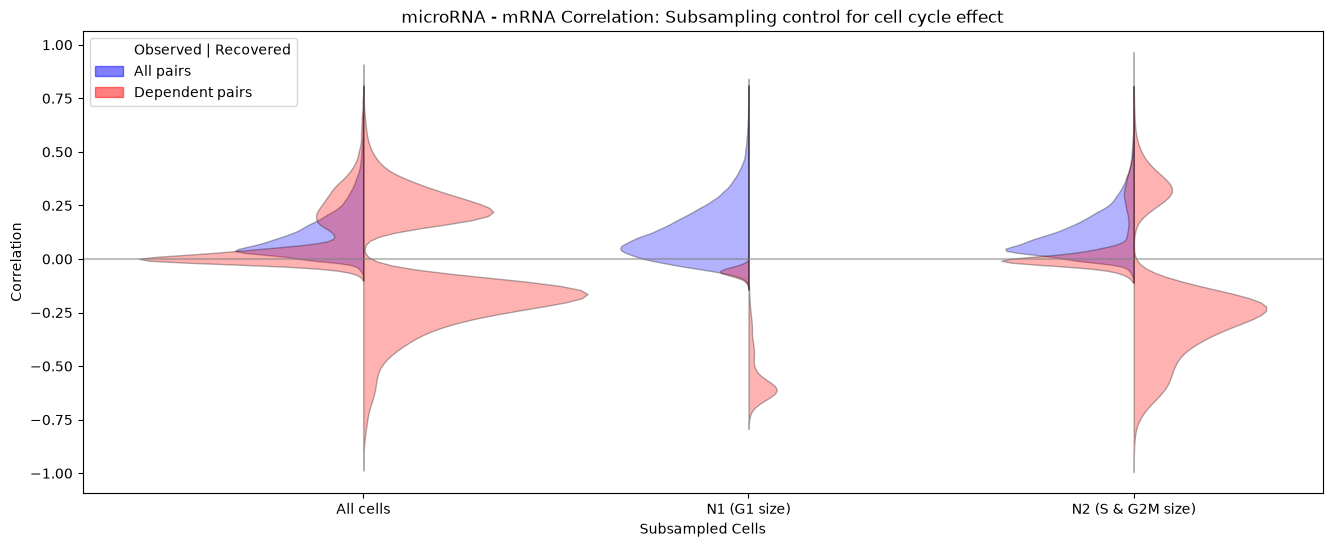

In [225]:
fig, axs = plt.subplots(figsize=(16, 6))

# width scaling
k = 2

# all observed
plot_data_list = [
    all_corr_OB,
    N1_corr_OB,
    N2_corr_OB
]
total_size = sum([dt.size for dt in plot_data_list])
for i, plot_data in enumerate(plot_data_list):
    vp = axs.violinplot(
        dataset=plot_data,
        positions=[i],
        showextrema=False,
        side="low",
        widths=k * (plot_data.size / total_size)
    )
    vp['bodies'][0].set_facecolor("blue")
    vp['bodies'][0].set_edgecolor("black")

# interacting observed
plot_data_list = [
    all_corr_OB_int,
    N1_corr_OB_int,
    N2_corr_OB_int
]
total_size = sum([dt.size for dt in plot_data_list])
for i, plot_data in enumerate(plot_data_list):
    vp = axs.violinplot(
        dataset=plot_data,
        positions=[i],
        showextrema=False,
        side="low",
        widths=k * (plot_data.size / total_size)
    )
    vp['bodies'][0].set_facecolor("red")
    vp['bodies'][0].set_edgecolor("black")

# interacting recovered
plot_data_list = [
    all_corr_HR,
    N1_corr_HR,
    N2_corr_HR
]
total_size = sum([dt.size for dt in plot_data_list])
for i, plot_data in enumerate(plot_data_list):
    vp = axs.violinplot(
        dataset=plot_data,
        positions=[i],
        showextrema=False,
        side="high",
        widths=k * (plot_data.size / total_size)
    )
    vp['bodies'][0].set_facecolor("red")
    vp['bodies'][0].set_edgecolor("black")


plt.axvspan(0, 0, 0, 0, color="white", label="Observed | Recovered")
plt.axvspan(0, 0, 0, 0, alpha=0.5, color="blue", label="All pairs")
plt.axvspan(0, 0, 0, 0, alpha=0.5, color="red", label="Dependent pairs")
axs.legend()

axs.axhline(0, color="grey", alpha=0.5)
axs.set_xticks([0, 1, 2])
axs.set_xticklabels(["All cells", "N1 (G1 size)", "N2 (S & G2M size)"])
axs.set_xlabel("Subsampled Cells")
axs.set_ylabel(f"Correlation")
axs.set_title("microRNA - mRNA Correlation: Subsampling control for cell cycle effect")
plt.show()

## Interval bounds: cell cycle vs subsampling control

In [226]:
all_corr_lb = MF_int_df[[col for col in MF_int_df.columns if "All_HAR_min" in col]].values.flatten()
all_corr_lb = all_corr_lb[~np.isnan(all_corr_lb)]

G1_corr_lb = MF_int_df[[col for col in MF_int_df.columns if "G1_HAR_min" in col]].values.flatten()
G1_corr_lb = G1_corr_lb[~np.isnan(G1_corr_lb)]

S_corr_lb = MF_int_df[[col for col in MF_int_df.columns if "S_HAR_min" in col]].values.flatten()
S_corr_lb = S_corr_lb[~np.isnan(S_corr_lb)]

G2M_corr_lb = MF_int_df[[col for col in MF_int_df.columns if "G2M_HAR_min" in col]].values.flatten()
G2M_corr_lb = G2M_corr_lb[~np.isnan(G2M_corr_lb)]

In [227]:
all_corr_ub = MF_int_df[[col for col in MF_int_df.columns if "All_HAR_max" in col]].values.flatten()
all_corr_ub = all_corr_ub[~np.isnan(all_corr_ub)]

G1_corr_ub = MF_int_df[[col for col in MF_int_df.columns if "G1_HAR_max" in col]].values.flatten()
G1_corr_ub = G1_corr_ub[~np.isnan(G1_corr_ub)]

S_corr_ub = MF_int_df[[col for col in MF_int_df.columns if "S_HAR_max" in col]].values.flatten()
S_corr_ub = S_corr_ub[~np.isnan(S_corr_ub)]

G2M_corr_ub = MF_int_df[[col for col in MF_int_df.columns if "G2M_HAR_max" in col]].values.flatten()
G2M_corr_ub = G2M_corr_ub[~np.isnan(G2M_corr_ub)]

In [228]:
all_corr_lb = MF_int_df[[col for col in MF_int_df.columns if "All_HAR_min" in col]].values.flatten()
all_corr_lb = all_corr_lb[~np.isnan(all_corr_lb)]

N1_corr_lb = MF_int_df[[col for col in MF_int_df.columns if "N1_HAR_min" in col]].values.flatten()
N1_corr_lb = N1_corr_lb[~np.isnan(N1_corr_lb)]

N2_corr_lb = MF_int_df[[col for col in MF_int_df.columns if "N2_HAR_min" in col]].values.flatten()
N2_corr_lb = N2_corr_lb[~np.isnan(N2_corr_lb)]

In [229]:
all_corr_ub = MF_int_df[[col for col in MF_int_df.columns if "All_HAR_max" in col]].values.flatten()
all_corr_ub = all_corr_ub[~np.isnan(all_corr_ub)]

N1_corr_ub = MF_int_df[[col for col in MF_int_df.columns if "N1_HAR_max" in col]].values.flatten()
N1_corr_ub = N1_corr_ub[~np.isnan(N1_corr_ub)]

N2_corr_ub = MF_int_df[[col for col in MF_int_df.columns if "N2_HAR_max" in col]].values.flatten()
N2_corr_ub = N2_corr_ub[~np.isnan(N2_corr_ub)]

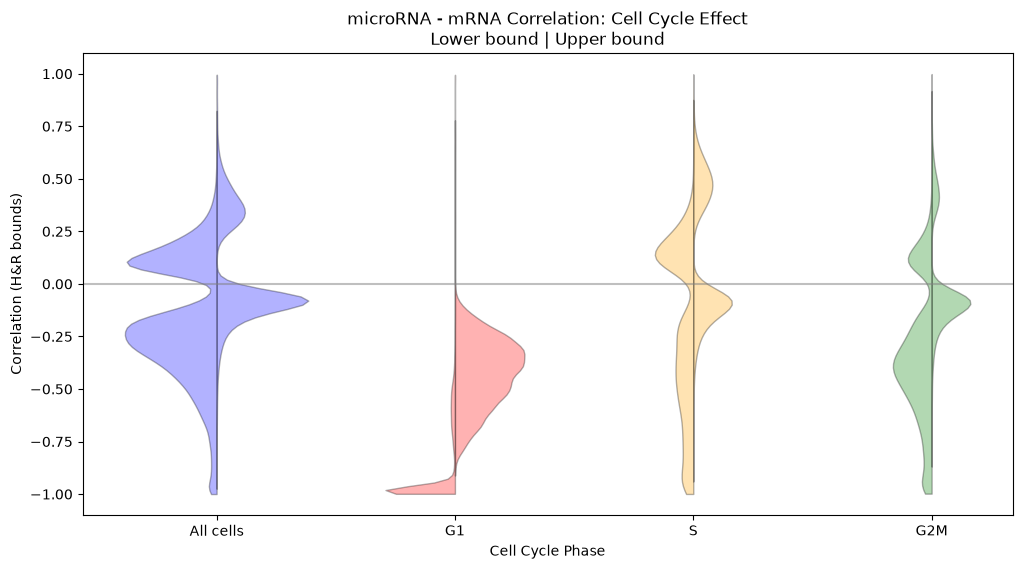

In [230]:
fig, axs = plt.subplots(figsize=(12, 6))
k = 2
plot_colors = ["blue", "red", "orange", "green"]
plot_data_list_lb = [
    all_corr_lb,
    G1_corr_lb,
    S_corr_lb,
    G2M_corr_lb
]
plot_data_list_ub = [
    all_corr_ub,
    G1_corr_ub,
    S_corr_ub,
    G2M_corr_ub
]
total_size_lb = sum([dt.size for dt in plot_data_list_lb])
total_size_ub = sum([dt.size for dt in plot_data_list_ub])
for i, (plot_data_lb, plot_data_ub) in enumerate(zip(plot_data_list_lb, plot_data_list_ub)):
    vp = axs.violinplot(
        dataset=plot_data_lb,
        positions=[i],
        showextrema=False,
        side="low",
        widths=k * (plot_data_lb.size / total_size_lb)
    )
    vp['bodies'][0].set_facecolor(plot_colors[i])
    vp['bodies'][0].set_edgecolor("black")
    vp = axs.violinplot(
            dataset=plot_data_ub,
            positions=[i],
            showextrema=False,
            side="high",
        widths=k * (plot_data_ub.size / total_size_ub)
        )
    vp['bodies'][0].set_facecolor(plot_colors[i])
    vp['bodies'][0].set_edgecolor("black")

axs.axhline(0, color="grey", alpha=0.5)
axs.set_xticks([0, 1, 2, 3])
axs.set_xticklabels(["All cells", "G1", "S", "G2M"])
axs.set_xlabel("Cell Cycle Phase")
axs.set_ylabel(f"Correlation (H&R bounds)")
axs.set_title("microRNA - mRNA Correlation: Cell Cycle Effect\nLower bound | Upper bound")
plt.show()

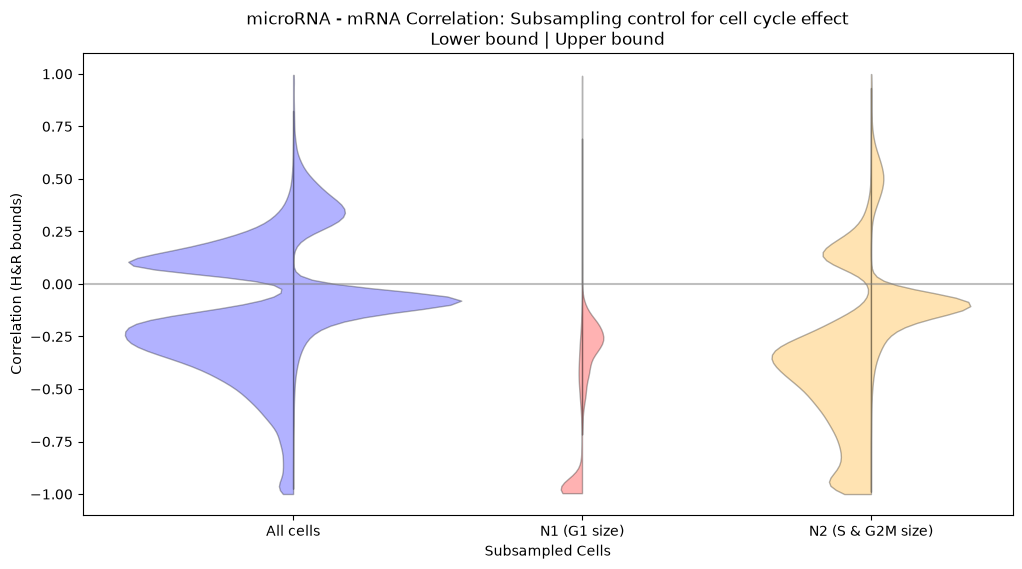

In [231]:
fig, axs = plt.subplots(figsize=(12, 6))
k = 2
plot_colors = ["blue", "red", "orange", "green"]
plot_data_list_lb = [
    all_corr_lb,
    N1_corr_lb,
    N2_corr_lb
]
plot_data_list_ub = [
    all_corr_ub,
    N1_corr_ub,
    N2_corr_ub
]
total_size_lb = sum([dt.size for dt in plot_data_list_lb])
total_size_ub = sum([dt.size for dt in plot_data_list_ub])
for i, (plot_data_lb, plot_data_ub) in enumerate(zip(plot_data_list_lb, plot_data_list_ub)):
    vp = axs.violinplot(
        dataset=plot_data_lb,
        positions=[i],
        showextrema=False,
        side="low",
        widths=k * (plot_data_lb.size / total_size_lb)
    )
    vp['bodies'][0].set_facecolor(plot_colors[i])
    vp['bodies'][0].set_edgecolor("black")
    vp = axs.violinplot(
            dataset=plot_data_ub,
            positions=[i],
            showextrema=False,
            side="high",
        widths=k * (plot_data_ub.size / total_size_ub)
        )
    vp['bodies'][0].set_facecolor(plot_colors[i])
    vp['bodies'][0].set_edgecolor("black")

axs.axhline(0, color="grey", alpha=0.5)
axs.set_xticks([0, 1, 2])
axs.set_xticklabels(["All cells", "N1 (G1 size)", "N2 (S & G2M size)"])
axs.set_xlabel("Subsampled Cells")
axs.set_ylabel(f"Correlation (H&R bounds)")
axs.set_title("microRNA - mRNA Correlation: Subsampling control for cell cycle effect\nLower bound | Upper bound")
plt.show()